# Flux post-processing chain: IRGA72 CO2 flux (2016-2026.09)

**notebook version**: `12` (29 Oct 2026). Adapted from the diive notebook `FluxPostProcessingChain.ipynb`.

## ℹ️ About this notebook

Processes a CO2 flux with the [diive flux post-processing chain](https://diive.readthedocs.io/en/latest/flux_postprocessing.html): storage term (L3.1),
outliers (L3.2), USTAR filter (L3.3), gap-filling (L4.1), partitioning (L4.2) and uncertainty.
The site, flux, period and all settings are in *Settings*; *Data sources* links the site
documentation, which holds the decisions and periods specific to the site.

`TEST_RUN = True` runs one year (`TEST_YEAR`) and writes its own output file.

***

## 📇 Data sources

The input `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09.parquet` in the
external data folder holds the Level-1 fluxes and the meteo data of the site.

Site documentation (CH-LAE): the processing levels, settings, periods removed by hand and known
limitations are on the [CH-LAE flux product site](https://holukas.github.io/dataset_ch-lae_flux_product/FPC.html), Levels 3.1 to 4.2.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"

# --- Testing -----------------------------------------------------------------------------------
# TEST_RUN = True processes only TEST_YEAR, a quick check of the whole notebook. A test run writes
# its own output file, so it never overwrites the result of a full run.
TEST_RUN = False
TEST_YEAR = 2025
# Years to process. None processes the whole record; set from TEST_RUN, or give a list of years.
YEARS = [TEST_YEAR] if TEST_RUN else None
RUN_PARTITIONING = True  # Level 4.2; not part of FP2026.1, which was released without it

# The full record, asserted after loading when YEARS is None.
PERIOD_START, PERIOD_END = '2016-01-01 00:15', '2026-09-30 23:45'

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "05_FPPC_IRGA72_NEE_2016-2026.09"  # same name as this notebook
if YEARS:
    OUTNAME += f"_TEST_{'_'.join(str(_y) for _y in YEARS)}"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'FC'  # CO2 flux of the closed-path LI-7200; no self-heating correction is needed
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
                        'method': 'discard below',
                        'threshold': 60},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.1 ---------------------------------------------------------------------------------
# The CO2 concentration the storage term SC_SINGLE is calculated from (mmol m-3). Next to a gap in
# it, the storage term is discarded where the analyser read off, and filled.
CO2_CONC = 'CO2_MOLAR_DENSITY'

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included). The reasons are in the
# site documentation (Level 3.2).
REMOVE_DATES = [
    ['2016-01-11', '2016-01-22'],  # LI-7200 installation, water in the filter
    ['2016-03-01', '2016-05-25'],  # too low a flow rate, water in the filter
    ['2018-12-30', '2019-01-10'],  # failing LI-7200 (IRGA72-B), replaced on 11 January 2019
    ['2020-11-08', '2020-11-27'],  # gas analyser fault: flux scatter, signal strength down to 60
    ['2020-12-04', '2020-12-06'],  # same fault, before the LI-7200 was replaced on 10 December
    ['2026-01-15', '2026-02-04'],  # raised scatter until the LI-7200 was cleaned on 4 February
]
# Absolute limits (umol m-2 s-1), as in the 2016-2024 notebooks.
ABSLIM = (-50, 50)

# --- Level 3.3 ---------------------------------------------------------------------------------
# Constant USTAR thresholds (m s-1), the 16th, 50th and 84th percentiles of the bootstrap
# detection of the 2016-2024 record (stage 32_). This dataset uses these fixed thresholds for the
# whole record.
USTAR_THRESHOLDS = [0.271619922, 0.303628125, 0.339684084]
USTAR_SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']

# --- Level 4.1 and 4.2: meteo drivers ----------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
TA_MEAS = 'TA_T1_47_1_HOMOGENIZED_MEASURED'  # built below from TA_F and TA_FLAG
SW_IN_MEAS = 'SW_IN_T1_47_1_MEASURED'        # built below from SW_IN_F and SW_IN_FLAG
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'µmol m-2 s-1'
RANDUNC_COL = 'FC_RANDUNC_HF'  # random uncertainty of FC from EddyPro
NIGHT_Z = 4  # night values below -NIGHT_Z times the pooled night spread are removed in Level 3.2

# 30-min CO2 flux in umol m-2 s-1 -> gC m-2 per half-hour, for sums and cumulatives.
UMOL_TO_GC = 12.011 * 1e-6 * 1800

# MDS gap-filling, next to XGBoost, to compare the two methods. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=1000, max_depth=6, learning_rate=0.05,
                    random_state=42, n_jobs=-1, shap_max_rows=5000)

# --- Uncertainty -------------------------------------------------------------------------------
# Pastorello et al. (2020): random uncertainty of the reference scenario, USTAR uncertainty from
# the two outer scenarios.
UNC_REF = 'CUT_50'
UNC_LOWER, UNC_UPPER = 'CUT_16', 'CUT_84'

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.plotting.styles import chainplots as cp
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.flux.postprocessingchain import (
    add_driver,
    init_flux_data,
    make_level32_detector,
    nighttime_uncertainty,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    run_level42_partitioning,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_tree_selection,
    plot_gapfilled_cumulative,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
    report_tree_selection,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-27 01:39:09
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
if YEARS:
    df = df.loc[df.index.year.isin(YEARS)].copy()
    assert len(df) > 0, f"no records for {YEARS}"
else:
    assert (df.index[0], df.index[-1]) == (pd.Timestamp(PERIOD_START), pd.Timestamp(PERIOD_END)), \
        f"the input runs from {df.index[0]} to {df.index[-1]}, not {PERIOD_START} to {PERIOD_END}"

for _c in [FLUXCOL, CO2_CONC, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet (0.221 seconds).

188,448 records x 347 columns, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
FC: 174,863 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'FC'
  levels run  = []
  fpc_df      = 188448 rows x 5 cols
  columns     = [FC, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The tests in `LEVEL2_SETTINGS`, e.g. steady state and developed turbulence (SSITC), the spectral
correction factor, the signal strength of the analyser and spikes and dropouts in the raw data
(Vickers and Mahrt 1997). The table shows how many records each test removes.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_FC_SSITC_TEST, values taken from output variable
FC_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_FC_SCF_TEST, newly 
calculated from output variable FC_SCF, with flag 0 (good values) where FC_SCF < 2, flag 1 (ok 
values) where FC_SCF >= 2 and < 4, flag 2 (bad values) where FC_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_FC_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN, with flag 0 (good values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN >= 60, flag 2 (bad values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN < 60 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_SPIKE_HF_TEST, values taken from 
output variable CO2_VM97_TEST from position 1, based on CO2, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_DROPOUT_HF_TEST, values taken 
from output variable CO2_VM97_TEST from position 3, based on CO2, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 134,315 valid records


### 📊 Plot: Level-2 quality flag over time

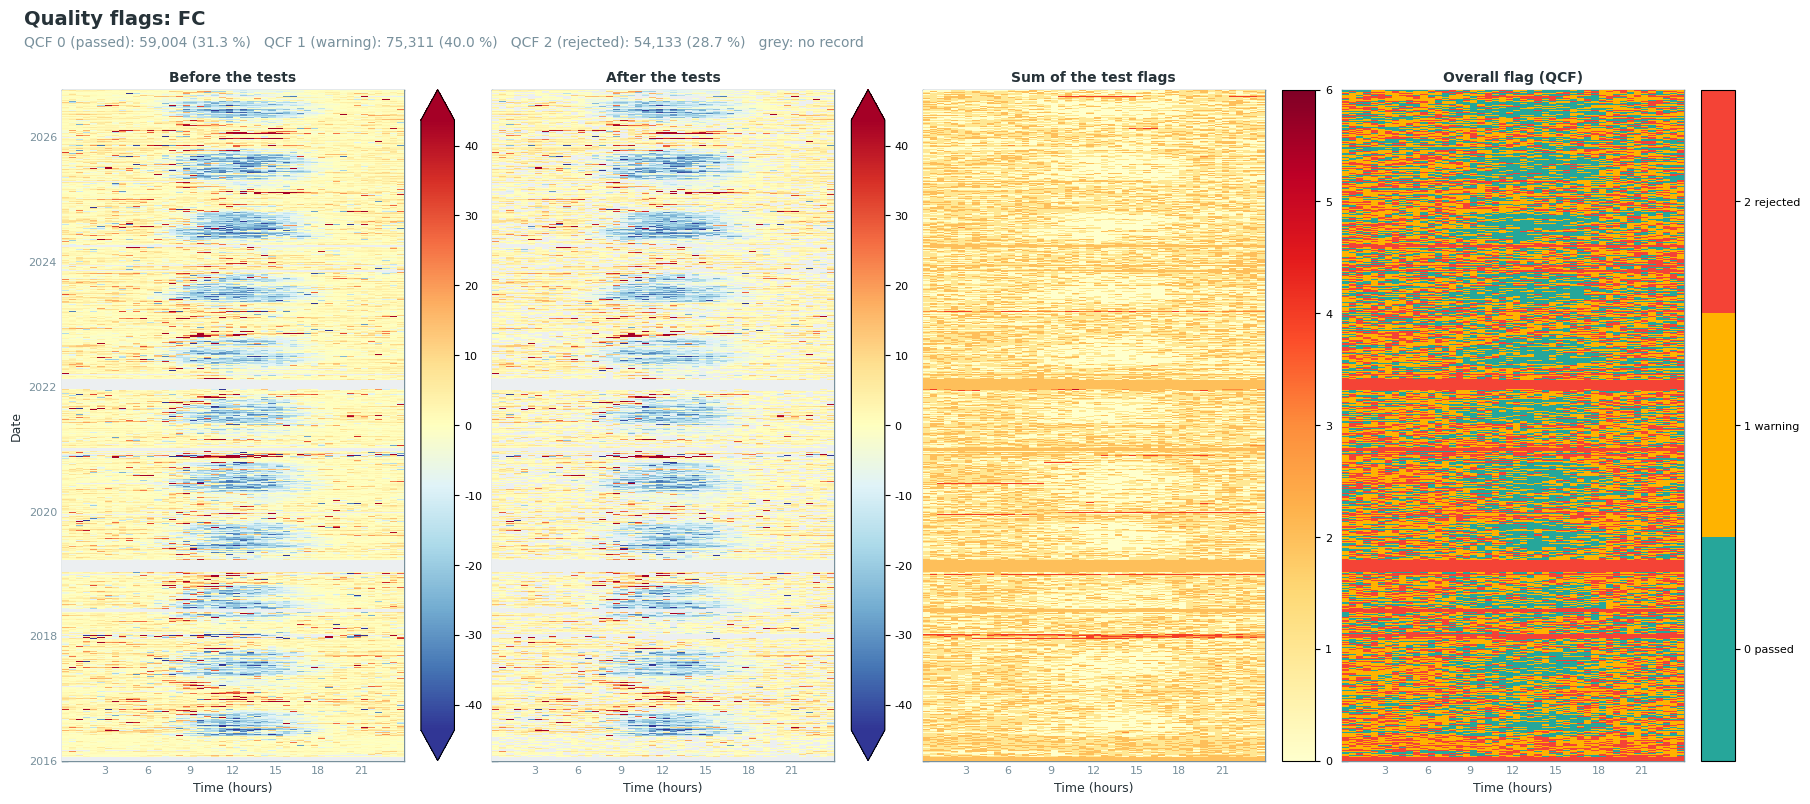

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: FC
Measured records: 174,863 of 188,448
Missing records: 13,585 (7.21 %), flagged by the missing-values test
                                                  Pass     Warn     Fail    Fail      Not
Test                        Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                 all      174,863    59,224   75,971   39,668   22.69        0
                            day       88,760    36,411   35,941   16,408   18.49        0
                            night     86,103    22,813   40,030   23,260   27.01        0
                                                                                         
L2_FC_SCF                   all      174,863   174,631      193       39    0.02        0
                            day       88,760    88,663       82       15    0.02        0
                            night     86,103    85,968      111       24    0.03        0
                                                                                         
L2_FC_SIGNAL_STRENGTH       all      174,863   173,593        0    1,270    0.73        0
                            day       88,760    88,273        0      487    0.55        0
                            night     86,103    85,320        0      783    0.91        0
                                                                                         
L2_FC_CO2_VM97_SPIKE_HF     all      174,863   174,830        0       33    0.02        0
                            day       88,760    88,754        0        6   <0.01        0
                            night     86,103    86,076        0       27    0.03        0
                                                                                         
L2_FC_CO2_VM97_DROPOUT_HF   all      174,863   174,863        0        0    0.00        0
                            day       88,760    88,760        0        0    0.00        0
                            night     86,103    86,103        0        0    0.00        0

## Step 3: storage term (Level 3.1)

Adds the storage term to the flux (`FC + SC_SINGLE`), after two screening steps:

- **Next to gaps** in `CO2_CONC`: after a signal loss an analyser can restart far from the real
  concentration, and its return would count as a one-sided storage flux. The storage values are
  discarded until the concentration is normal again for its time of day.
- **Spikes**: each isolated spike, with one record on either side, is replaced by the block mean,
  which keeps the sum.

The removed values are filled with a rolling median, so every measured flux keeps a storage term.
Details: [diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#storage-term).

In [8]:
data = run_level31(data, gapfill_storage_term=True, set_storage_to_zero=False,
                   screen_storage_term=True, concentration_col=CO2_CONC)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux NEE_L3.1 from flux FC + storage term SC_SINGLE

> Storage term SC_SINGLE: 116 analyser restart(s) after a gap in CO2_MOLAR_DENSITY; 480 storage 
value(s) discarded where the concentration was off next to a gap

> Storage term SC_SINGLE: 4,534 spike(s) found (2.61 % of the measured storage values)

> Storage term SC_SINGLE: 9,989 value(s) replaced by the mean of their block (spikes and one 
record on either side)

After L3.1: 134,315 valid records (col: NEE_L3.1_QCF)


### 📊 Plot: storage term screening

The daily cycle should stay positive at night with a dip in the morning, the spikes should have
both signs, and the cumulative sum should stay near zero. A drift that remains usually lies in
periods when the analyser was failing; check that the quality flags remove their fluxes.

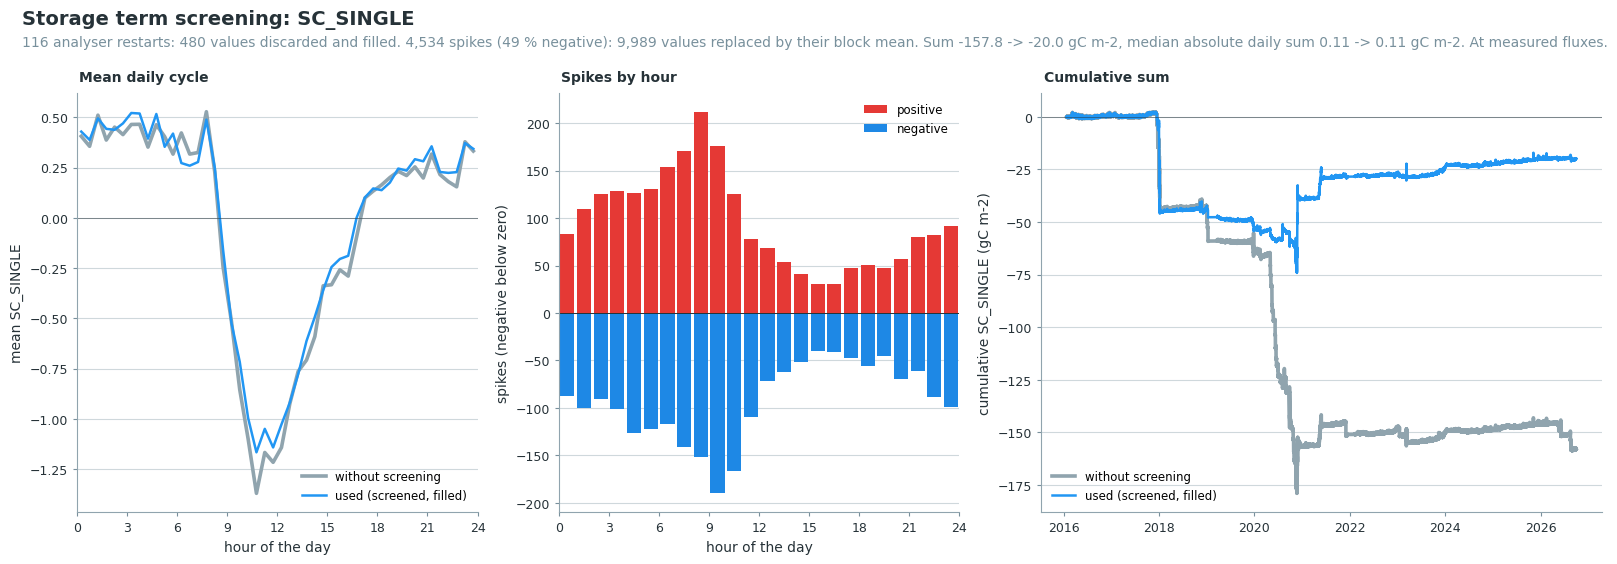

In [9]:
data.levels.level31.plot_screening(gain=UMOL_TO_GC, units='gC m-2');

## Step 4: outlier removal (Level 3.2)

Five tests. Check each plot, then accept the test with `sod.addflag()` in the cell below it.

1. Periods in `REMOVE_DATES`, removed by hand; the reasons are in the site documentation.
2. Absolute limits `ABSLIM`.
3. Hampel filter on double differences: single spikes.
4. Hampel filter per time of day: values wrong for their time of day.
5. Nighttime values clearly below zero.

How the tests work: [diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#outlier-tests). The table at the end of this step lists
further tests.

In [10]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

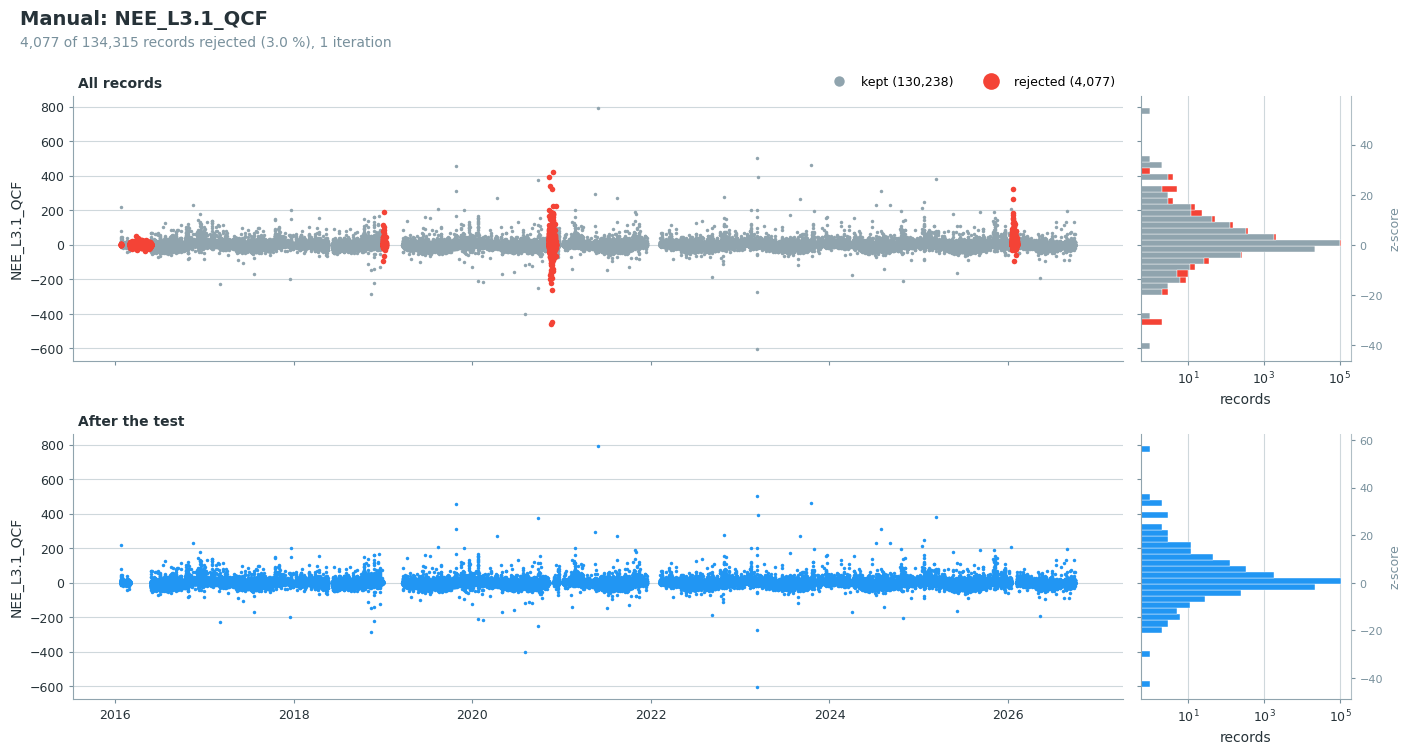

In [11]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [12]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

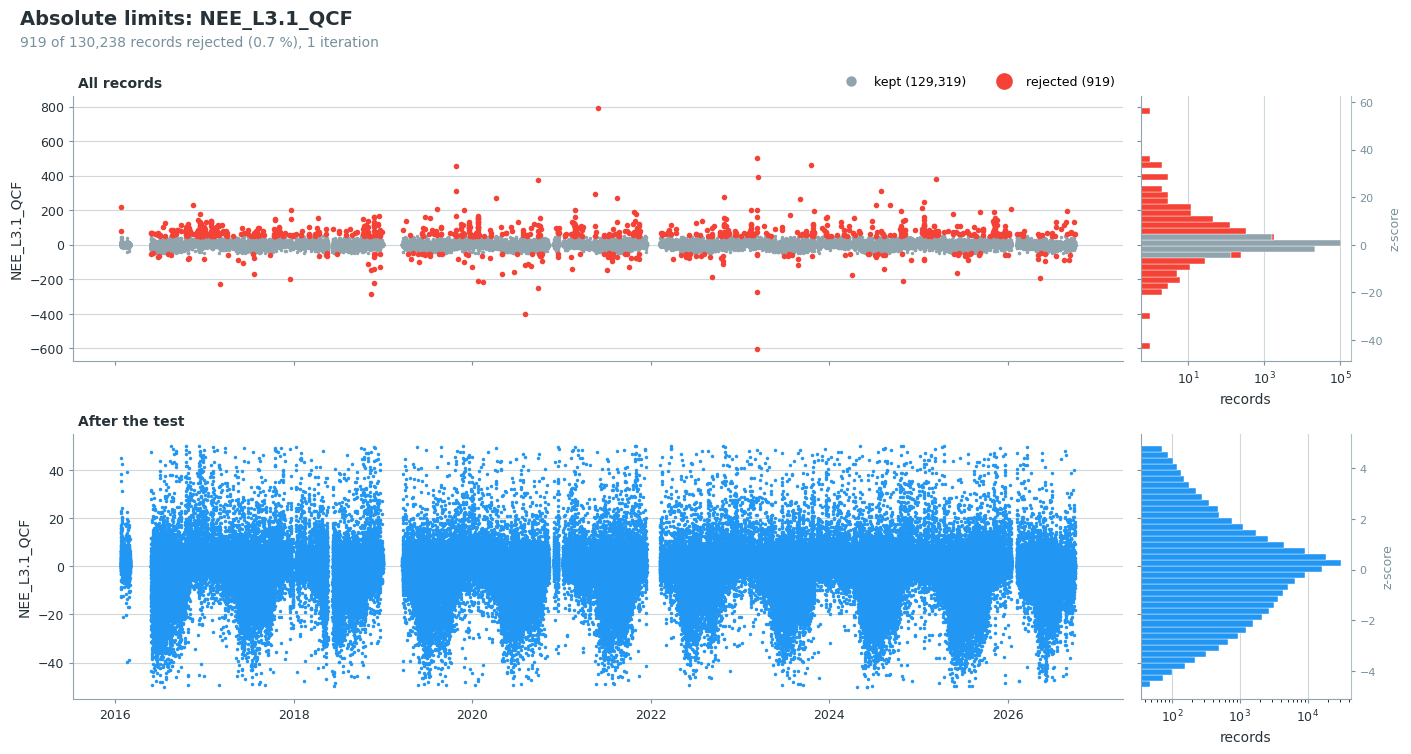

In [13]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [14]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  2538 (  1.96%) | Day:  1073 | Night:  1465

[Dt/Nt] ITER #02 | Outliers:   306 (  0.24%) | Day:   117 | Night:   189

[Dt/Nt] ITER #03 | Outliers:    69 (  0.05%) | Day:    30 | Night:    39

[Dt/Nt] ITER #04 | Outliers:    11 (  0.01%) | Day:     7 | Night:     4

[Dt/Nt] ITER #05 | Outliers:     2 (  0.00%) | Day:     0 | Night:     2

[Dt/Nt] ITER #06 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

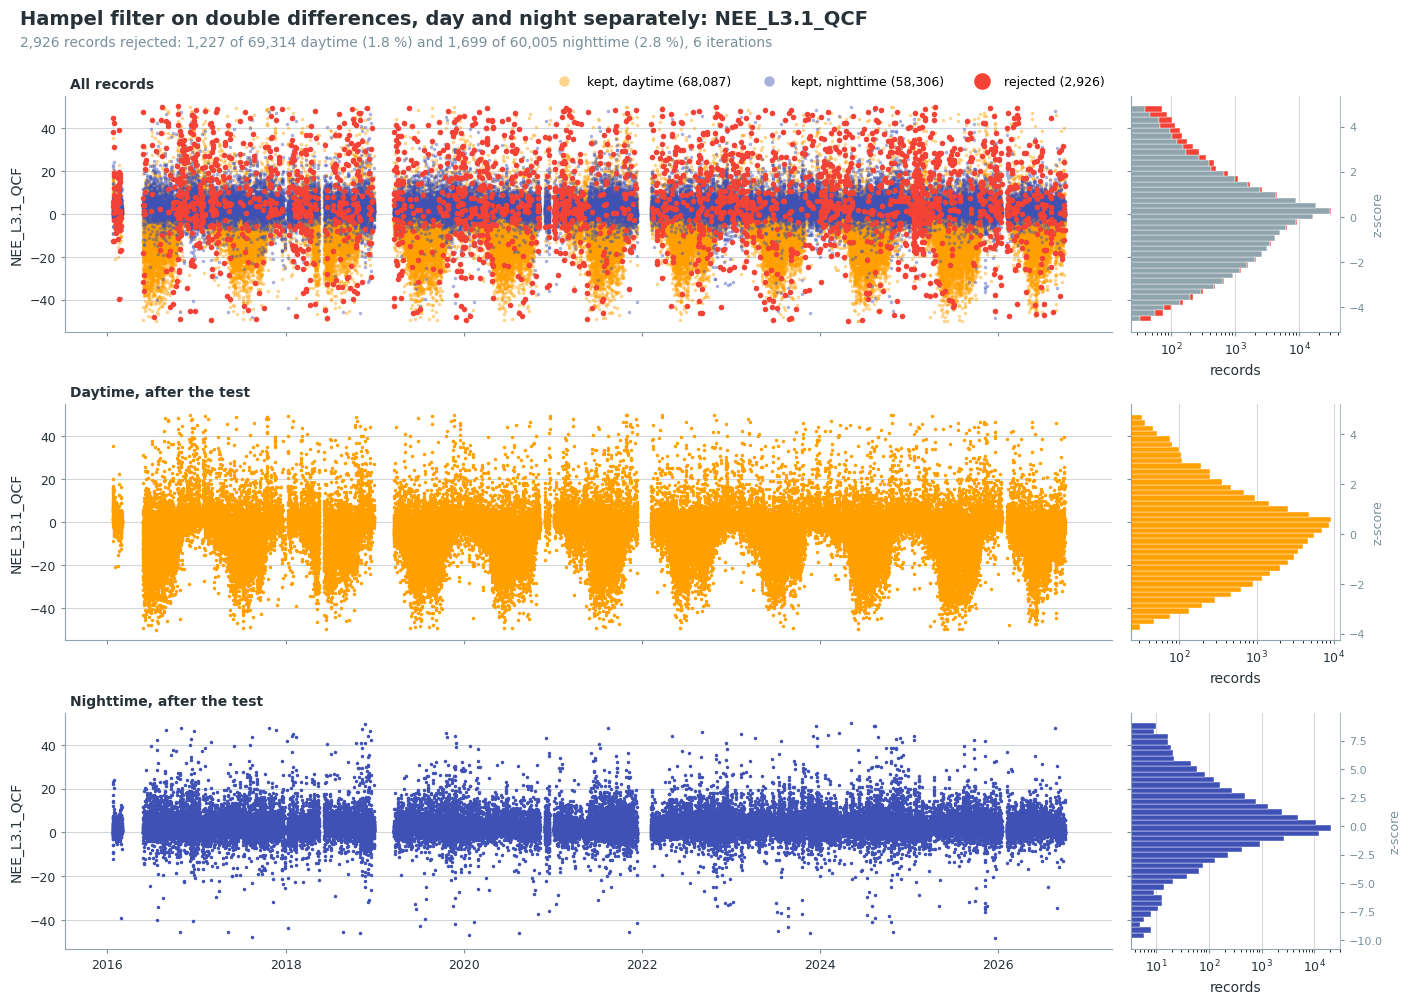

In [15]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [16]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  2065 (  1.63%) | Day:   862 | Night:  1203

[Dt/Nt] ITER #02 | Outliers:   257 (  0.21%) | Day:   115 | Night:   142

[Dt/Nt] ITER #03 | Outliers:    27 (  0.02%) | Day:    14 | Night:    13

[Dt/Nt] ITER #04 | Outliers:     5 (  0.00%) | Day:     1 | Night:     4

[Dt/Nt] ITER #05 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

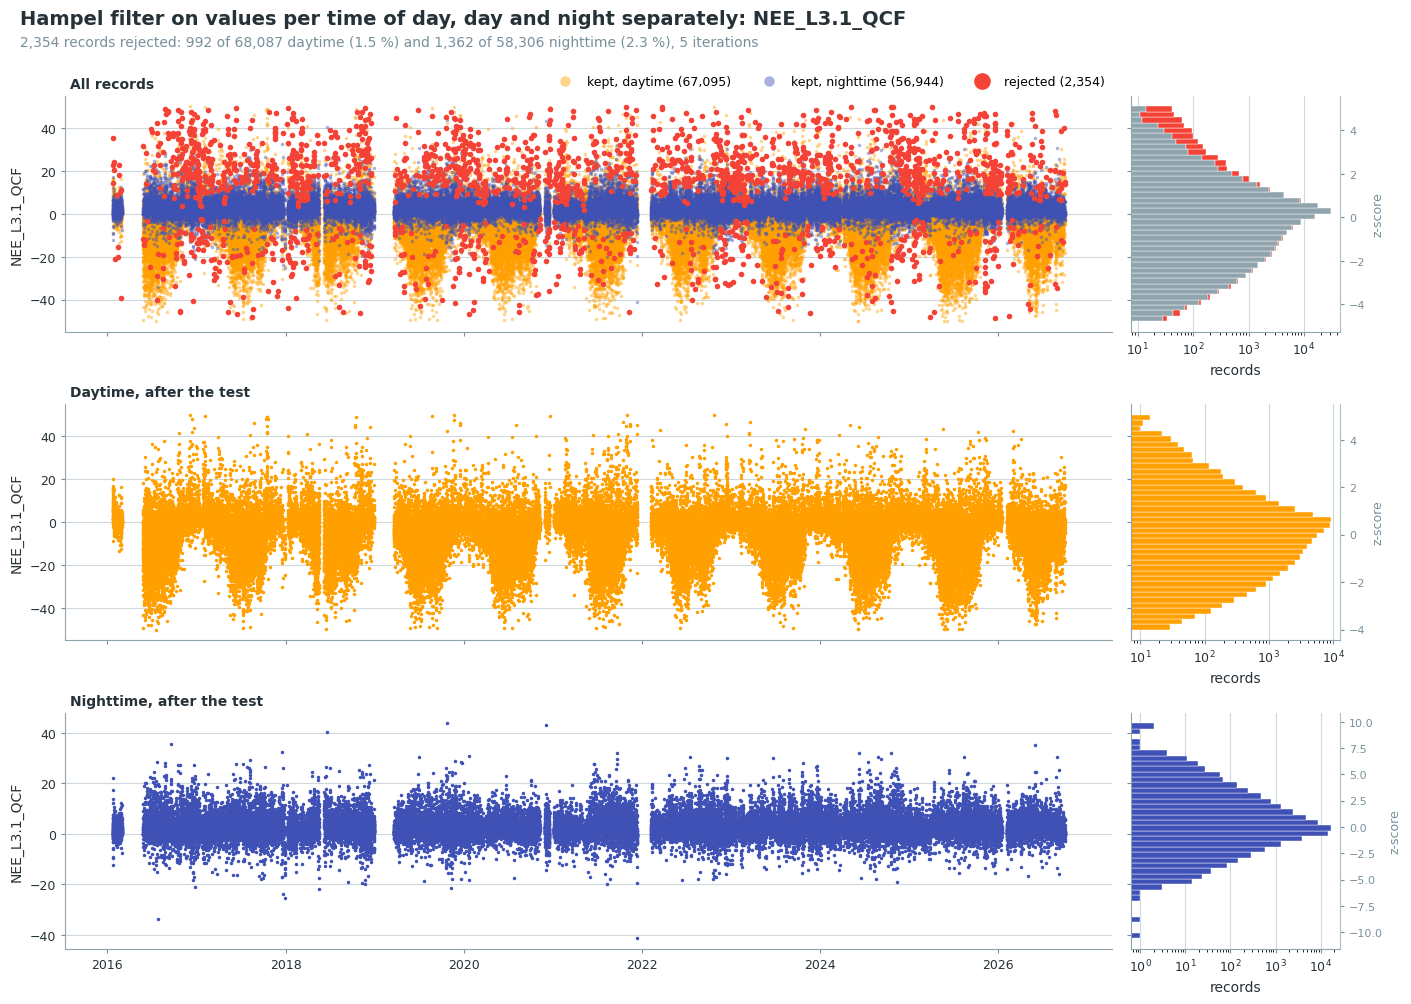

In [17]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [18]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### Negative values at night

At night the flux is respiration, so its true value is zero or above, and only noise pushes it
below zero. Test 5 removes nighttime values below `-NIGHT_Z` times `POOLED`, the robust spread
of all nighttime values within ±15 days. Unlike the per-record uncertainties in the table, it does
not grow with a few bad values in a noisy stretch. High values are not tested
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#negative-nighttime)).

### 📋 Table: random uncertainty of the nighttime records

In [19]:
sigma = nighttime_uncertainty(data, sod, randunc_col=RANDUNC_COL, ta=TA_F, vpd=VPD_F, swin=SW_IN_F)

Random uncertainty of the 56,944 nighttime records
uncertainty   median at night   below -2 sigma   below -3 sigma
───────────────────────────────────────────────────────────────
FS                       0.77    5,192 (9.1 %)    3,620 (6.4 %)
PAS20                    3.32      376 (0.7 %)       26 (0.0 %)
MAX                      3.35      329 (0.6 %)       20 (0.0 %)
POOLED                   2.70    1,057 (1.9 %)      425 (0.7 %)
FS: EddyPro, sampling error of each half-hour. PAS20: spread of similar measurements (ONEFlux), a 
generous estimate. MAX: the larger of the two. POOLED: spread of all nighttime values within 15 days
on either side.

### 📊 Plot: nighttime values clearly below zero

> Nighttime records below -4 uncertainties: 180. Expected from noise alone (Gaussian): 0.1 
records, raising the sum by 1.05 (flux units x records) once their gaps are filled.

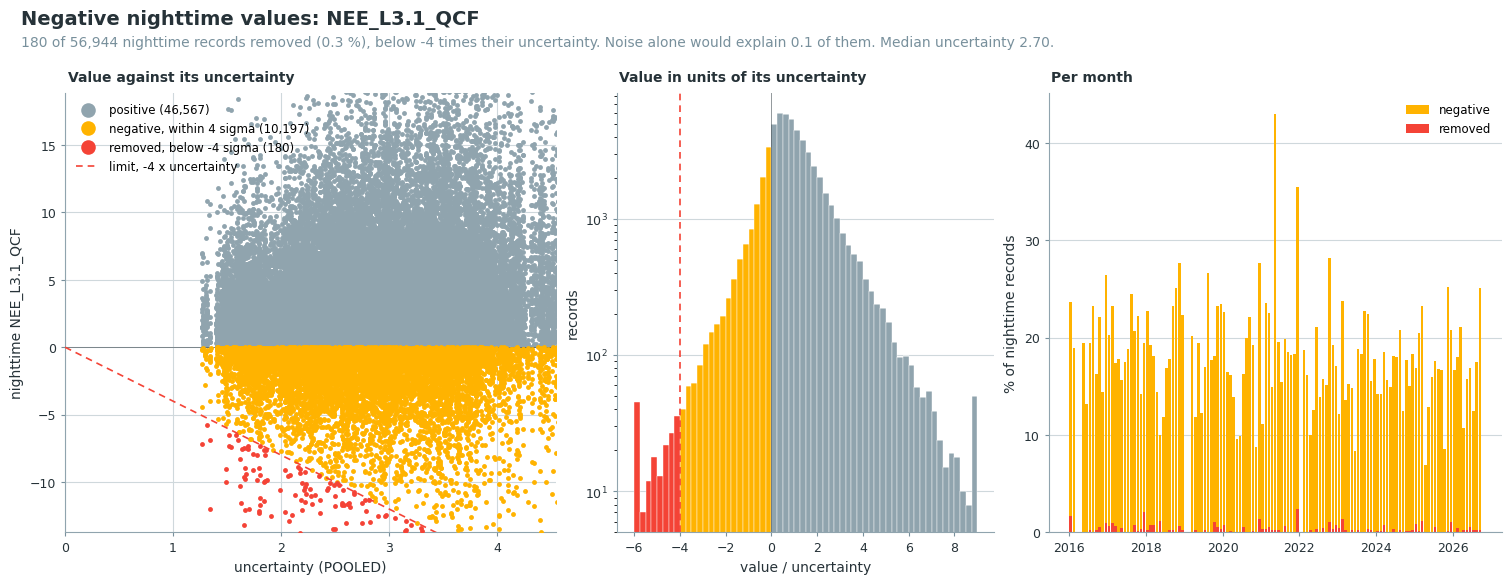

In [20]:
sod.flag_outliers_negative_night_test(uncertainty=sigma['POOLED'], z=NIGHT_Z, showplot=True, verbose=True)

In [21]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [22]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test',
         'flag_outliers_negative_night_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,yes
sod.flag_outliers_trim_low_test(),Flag values below a given absolute limit as ou...,


### Apply the Level-3.2 flags

In [23]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 123,859 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

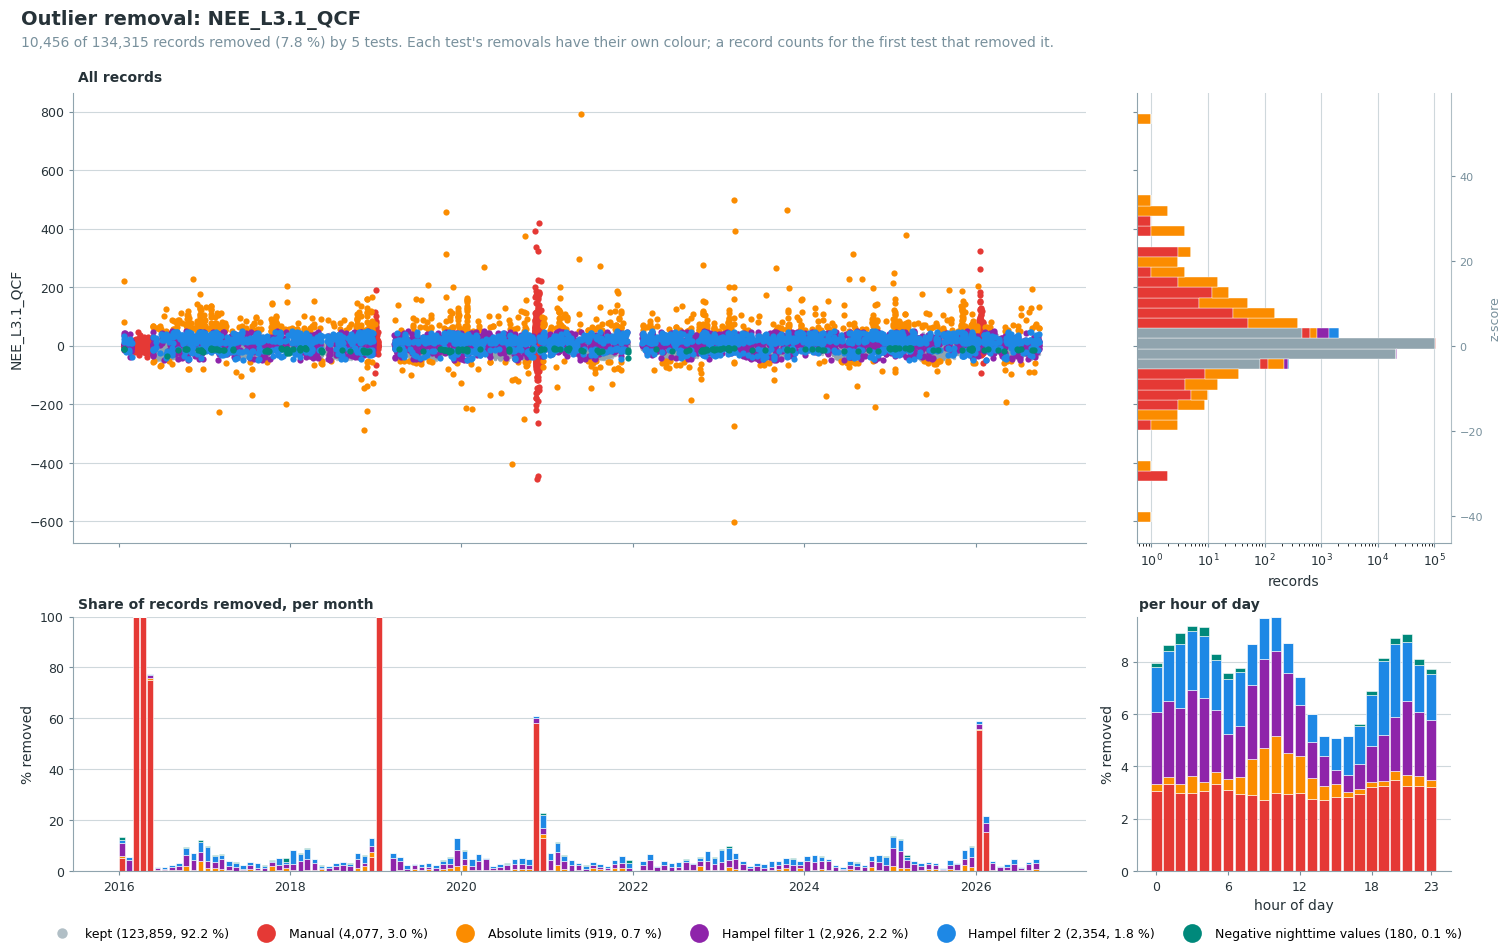

In [24]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

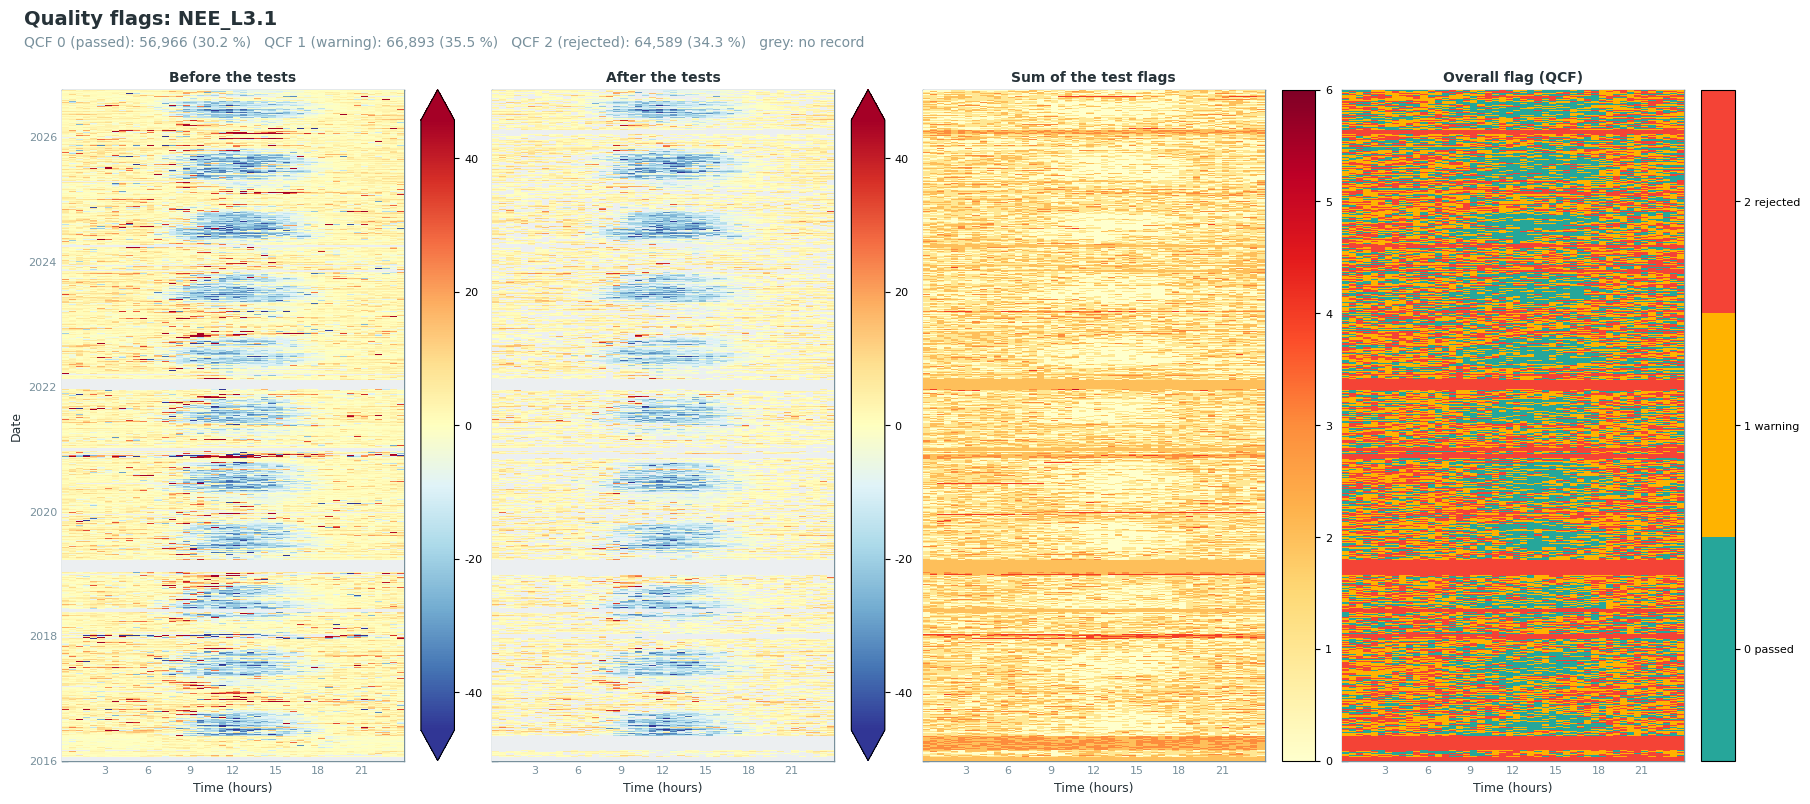

In [25]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [26]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: NEE_L3.1
Measured records: 174,863 of 188,448
Missing records: 13,585 (7.21 %), flagged by the missing-values test
                                                           Pass     Warn     Fail    Fail      Not
Test                                 Period    Tested       (0)      (1)      (2)       %   tested
──────────────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                          all      174,863    59,224   75,971   39,668   22.69        0
                                     day       88,760    36,411   35,941   16,408   18.49        0
                                     night     86,103    22,813   40,030   23,260   27.01        0
                                                                                                  
L2_FC_SCF                            all      174,863   174,631      193       39    0.02        0
                                     day       88,760    88,663       82       15    0.02        0
                                     night     86,103    85,968      111       24    0.03        0
                                                                                                  
L2_FC_SIGNAL_STRENGTH                all      174,863   173,593        0    1,270    0.73        0
                                     day       88,760    88,273        0      487    0.55        0
                                     night     86,103    85,320        0      783    0.91        0
                                                                                                  
L2_FC_CO2_VM97_SPIKE_HF              all      174,863   174,830        0       33    0.02        0
                                     day       88,760    88,754        0        6   <0.01        0
                                     night     86,103    86,076        0       27    0.03        0
                                                                                                  
L2_FC_CO2_VM97_DROPOUT_HF            all      174,863   174,863        0        0    0.00        0
                                     day       88,760    88,760        0        0    0.00        0
                                     night     86,103    86,103        0        0    0.00        0
                                                                                                  
L3.2_NEE_L3.1_QCF_OUTLIER_MANUAL     all      134,315   130,238        0    4,077    3.04   40,548
                                     day       72,015    70,015        0    2,000    2.78   16,745
                                     night     62,300    60,223        0    2,077    3.33   23,803
                                                                                                  
L3.2_NEE_L3.1_QCF_OUTLIER_ABSLIM     all      130,238   129,319        0      919    0.71   44,625
                                     day       70,015    69,314        0      701    1.00   18,745
                                     night     60,223    60,005        0      218    0.36   25,880
                                                                                                  
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL     all      129,319   126,393        0    2,926    2.26   45,544
                                     day       69,314    68,087        0    1,227    1.77   19,446
                                     night     60,005    58,306        0    1,699    2.83   26,098
                                                                                                  
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2   all      126,393   124,039        0    2,354    1.86   48,470
                                     day       68,087    67,095        0      992    1.46   20,673
                                     night     58,306    56,944        0    1,362    2.34   27,797
                                                                                                  
L3.2_NEE_L3.

## Step 5: USTAR filter (Level 3.3)

Removes records with USTAR below the threshold, by day and by night; unlike ONEFlux, the first
record above it is kept. One scenario per threshold in `USTAR_THRESHOLDS`
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#ustar-filter)).

In [27]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_16

> QCF computed for USTAR scenario CUT_50

> QCF computed for USTAR scenario CUT_84

### Records for gap-filling and highest-quality records

The records the gap-filling starts from (QCF 0 and 1, columns `_QCF`) and the highest-quality
records (QCF 0, columns `_QCF0`) for analyses without gap-filled values
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#gapfilling-input)).

### 📋 Table: records per USTAR scenario

In [28]:
report_gapfilling_input(data);

Records for gap-filling
                    removed:   removed:             used:    used:    used:    used:
USTAR    measured      tests      USTAR     used    QCF 0    QCF 1      day    night
────────────────────────────────────────────────────────────────────────────────────
CUT_16    174,863     51,004     31,447   92,412   49,090   43,322   55,024   37,388
              93%        27%        17%      49%      26%      23%      29%      20%
CUT_50    174,863     51,004     37,102   86,757   46,827   39,930   51,969   34,788
              93%        27%        20%      46%      25%      21%      28%      18%
CUT_84    174,863     51,004     43,610   80,249   44,048   36,201   48,404   31,845
              93%        27%        23%      43%      23%      19%      26%      17%
Records, and their share of all 188,448 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

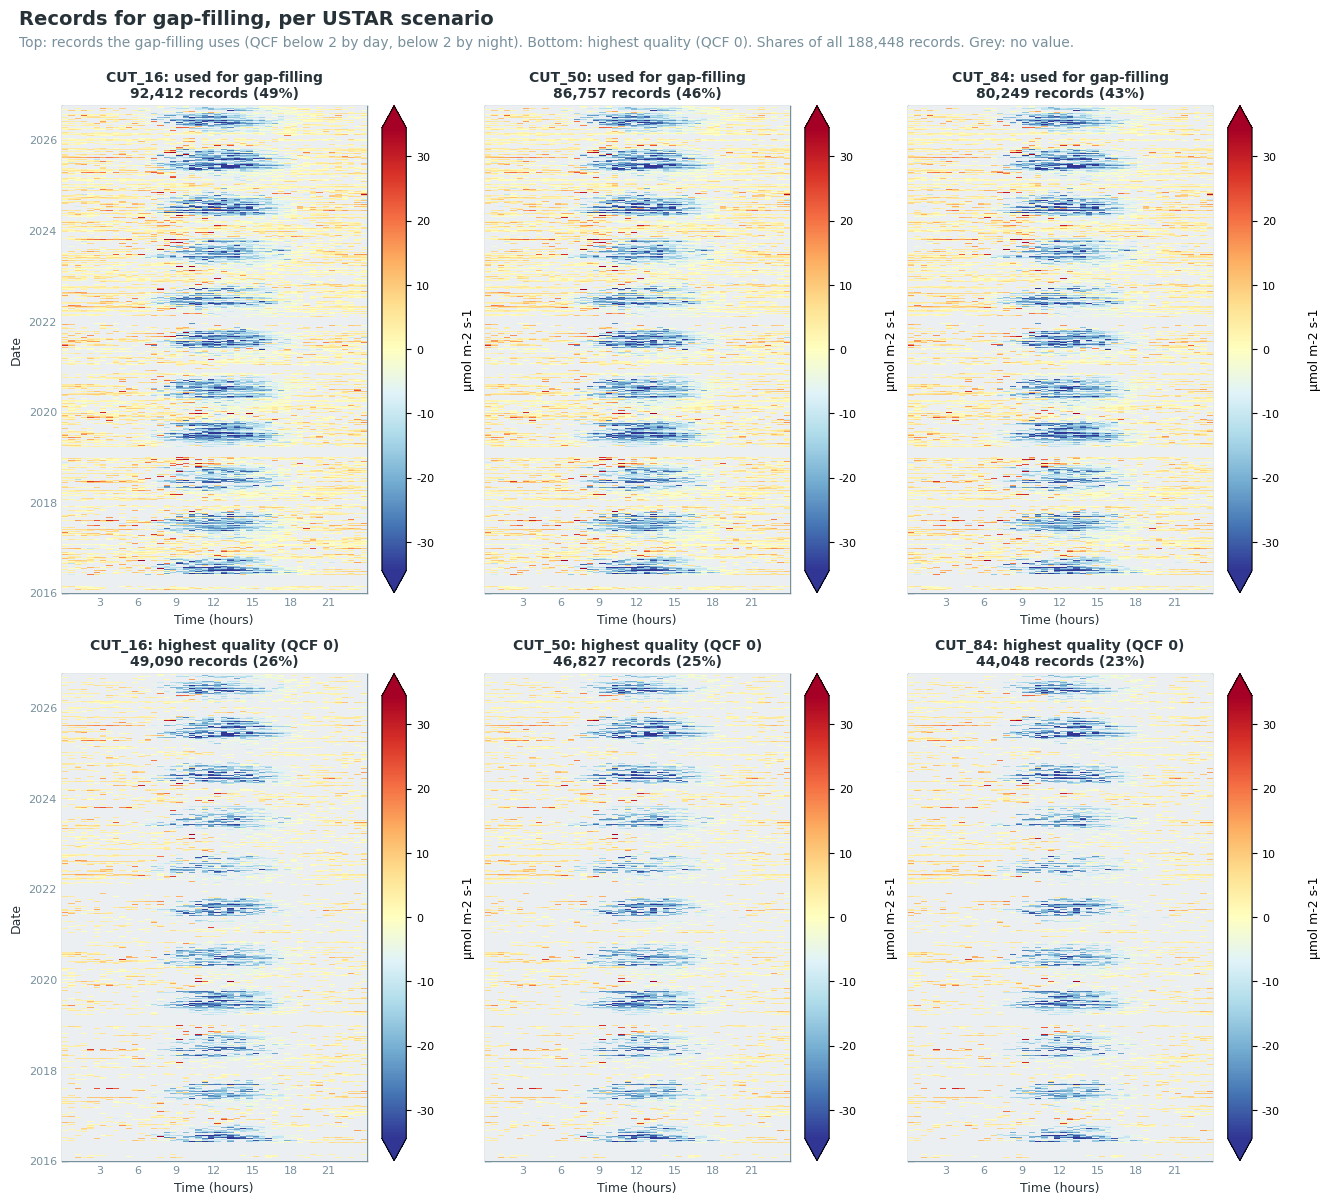

In [29]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps per USTAR scenario

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [30]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR    missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
─────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16        51.0   23752          38                 86.0           Jan                    64.8
CUT_50        54.0   22882          47                 86.4           Dec                    66.8
CUT_84        57.4   21753          69                 86.4           Dec                    69.9
A long gap lasts at least 1 day.

## Step 6: meteo drivers and model features

The ONEFlux partitioning needs measured temperature and radiation. These are the complete driver
series, restricted to the measured records. `add_driver` puts them into `data.full_df`,
where Levels 4.1 and 4.2 look for their drivers.

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [31]:
_ta_meas = df[TA_F].where(df[TA_FLAG] == 0).rename(TA_MEAS)
_sw_meas = df[SW_IN_F].where(df[SW_IN_FLAG] == 0).rename(SW_IN_MEAS)
data = add_driver(data, _ta_meas)
data = add_driver(data, _sw_meas)
print(f"{TA_MEAS}: {_ta_meas.notna().sum():,} measured records of {len(_ta_meas):,}")
print(f"{SW_IN_MEAS}: {_sw_meas.notna().sum():,} measured records of {len(_sw_meas):,}")

engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

TA_T1_47_1_HOMOGENIZED_MEASURED: 186,575 measured records of 188,448
SW_IN_T1_47_1_MEASURED: 186,603 measured records of 188,448


## Step 7: gap-filling (Level 4.1)

XGBoost fills the gaps of this dataset, MDS for comparison (Step 11).

### XGBoost

One model per year and USTAR scenario, trained on three years, with features selected by SHAP and
shared across the scenarios ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#xgboost-gapfilling)).

The number of trees is chosen once for all models by blocked cross-validation
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [32]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    n_estimators_cv=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) in `mode='diive'`, filling every gap from
measured driver values only ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#mds-gapfilling)).

**Skipped** when `RUN_MDS = False`.

In [33]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: partitioning into GPP and RECO (Level 4.2)

**Skipped** when `RUN_PARTITIONING = False`. Nighttime and daytime partitioning as in ONEFlux
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#partitioning)).

In [34]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='nighttime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        gapfill_method='xgb',
    )

In [35]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='daytime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        sw_in_f=SW_IN_F,
        vpd_f=VPD_F,  # kPa
        gapfill_method='xgb',
    )
    print(data.partitioned_cols())

## Step 9: results

How many records were measured and how many were filled, then the annual sum of the flux, for each
USTAR scenario. The share measured is given in brackets: a year with long gaps rests largely on the
model. An incomplete year is marked.

### 📋 Table: measured and filled records

In [36]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR    records   measured    filled   filled %
──────────────────────────────────────────────────────────
MDS       CUT_16   188,448     92,412    96,036       51.0
MDS       CUT_50   188,448     86,757   101,691       54.0
MDS       CUT_84   188,448     80,249   108,199       57.4
XGBoost   CUT_16   188,448     92,412    96,036       51.0
XGBoost   CUT_50   188,448     86,757   101,691       54.0
XGBoost   CUT_84   188,448     80,249   108,199       57.4
MDS (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfMDS
MDS (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfMDS
MDS (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfMDS
XGBoost (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfXG
XGBoost (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfXG
XGBoost (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfXG

### 📋 Table: annual sums of the flux

In [37]:
report_annual_sums(data, gain=UMOL_TO_GC, units='gC m-2');

Annual sums (gC m-2)
                MDS          MDS          MDS      XGBoost      XGBoost      XGBoost
year         CUT_16       CUT_50       CUT_84       CUT_16       CUT_50       CUT_84
────────────────────────────────────────────────────────────────────────────────────
2016     -301 (38%)   -277 (35%)   -232 (33%)   -149 (38%)   -119 (35%)    -91 (33%)
2017       -6 (52%)     25 (49%)     28 (45%)     51 (52%)     82 (49%)     95 (45%)
2018     -207 (48%)   -196 (46%)   -177 (42%)   -120 (48%)   -105 (46%)    -83 (42%)
2019     -314 (42%)   -306 (39%)   -306 (36%)   -271 (42%)   -265 (39%)   -265 (36%)
2020     -347 (49%)   -325 (46%)   -297 (43%)   -280 (49%)   -261 (46%)   -245 (43%)
2021      -55 (48%)    -52 (45%)    -20 (42%)    -16 (48%)    -11 (45%)      4 (42%)
2022      -86 (50%)    -69 (47%)    -43 (43%)    -31 (50%)    -16 (47%)     13 (43%)
2023      -32 (54%)    -15 (51%)     10 (47%)     -8 (54%)     10 (51%)     35 (47%)
2024      -63 (52%)    -40 (49%)    -13 (45%)    -51 (52%)    -36 (49%)     -7 (45%)
2025     -458 (55%)   -435 (51%)   -418 (47%)   -365 (55%)   -338 (51%)   -310 (47%)
2026 *   -350 (52%)   -336 (49%)   -309 (46%)   -298 (52%)   -284 (49%)   -257 (46%)
In brackets: the share of the year's records that were measured.
* Incomplete year (2026): the sum covers only part of it.

## Step 10: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. The number of trees is chosen without the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [38]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
XGBoost   CUT_16   2016   0.718   5.56   3.70    2.41   42.2
XGBoost   CUT_16   2017   0.718   5.56   3.70    2.41   42.2
XGBoost   CUT_16   2018   0.702   5.56   3.71    2.47   47.2
XGBoost   CUT_16   2019   0.713   5.60   3.64    2.27   56.0
XGBoost   CUT_16   2020   0.727   5.53   3.63    2.31   47.4
XGBoost   CUT_16   2021   0.730   5.36   3.48    2.19   46.3
XGBoost   CUT_16   2022   0.718   5.44   3.54    2.19   41.1
XGBoost   CUT_16   2023   0.740   5.16   3.44    2.23   43.7
XGBoost   CUT_16   2024   0.760   5.16   3.38    2.13   45.4
XGBoost   CUT_16   2025   0.765   5.10   3.36    2.13   42.4
XGBoost   CUT_16   2026   0.765   5.10   3.36    2.13   42.4
XGBoost   CUT_16   mean   0.732   5.38   3.54    2.26   45.1
                                                            
XGBoost   CUT_50   2016   0.703   5.81   3.79    2.34   43.0
XGBoost   CUT_50   2017   0.703   5.81   3.79    2.34   43.0
XGBoost   CUT_50   2018   0.709   5.71   3.76    2.38   44.0
XGBoost   CUT_50   2019   0.725   5.45   3.59    2.30   46.7
XGBoost   CUT_50   2020   0.723   5.73   3.70    2.26   47.4
XGBoost   CUT_50   2021   0.723   5.38   3.48    2.12   47.7
XGBoost   CUT_50   2022   0.725   5.26   3.44    2.15   45.4
XGBoost   CUT_50   2023   0.747   5.15   3.40    2.17   40.9
XGBoost   CUT_50   2024   0.740   5.44   3.50    2.16   46.4
XGBoost   CUT_50   2025   0.767   5.12   3.39    2.15   41.0
XGBoost   CUT_50   2026   0.767   5.12   3.39    2.15   41.0
XGBoost   CUT_50   mean   0.730   5.45   3.57    2.23   44.2
                                                            
XGBoost   CUT_84   2016   0.722   5.61   3.70    2.37   45.7
XGBoost   CUT_84   2017   0.722   5.61   3.70    2.37   45.7
XGBoost   CUT_84   2018   0.729   5.54   3.70    2.45   43.6
XGBoost   CUT_84   2019   0.754   5.23   3.51    2.26   39.5
XGBoost   CUT_84   2020   0.729   5.79   3.78    2.36   51.2
XGBoost   CUT_84   2021   0.738   5.37   3.49    2.14   47.8
XGBoost   CUT_84   2022   0.717   5.59   3.62    2.26   50.5
XGBoost   CUT_84   2023   0.772   5.01   3.40    2.27   47.6
XGBoost   CUT_84   2024   0.767   5.21   3.42    2.19   49.9
XGBoost   CUT_84   2025   0.784   5.11   3.37    2.09   44.0
XGBoost   CUT_84   2026   0.784   5.11   3.37    2.09   44.0
XGBoost   CUT_84   mean   0.747   5.38   3.55    2.26   46.3
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [39]:
report_model_overview(data);

Gap-filling models
                trained                                          final    test   test            fall-
USTAR    year   on          features    train    test   trees      fit      R²   RMSE   filled    back
──────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16   2016   2016-2018         98   18,187   6,063     110   24,250   0.718   5.56   10,907       0
CUT_16   2017   2016-2018         98   18,187   6,063     110   24,250   0.718   5.56    8,398       0
CUT_16   2018   2017-2019         98   18,708   6,237     110   24,945   0.702   5.56    9,053       0
CUT_16   2019   2018-2020         98   18,325   6,109     110   24,434   0.713   5.60   10,164       0
CUT_16   2020   2019-2021         98   18,319   6,107     110   24,426   0.727   5.53    8,957       0
CUT_16   2021   2020-2022         98   19,317   6,439     110   25,756   0.730   5.36    9,061       0
CUT_16   2022   2021-2023         98   19,929   6,643     110   26,572   0.718   5.44    8,834       0
CUT_16   2023   2022-2024         98   20,493   6,831     110   27,324   0.740   5.16    8,093       0
CUT_16   2024   2023-2025         98   21,166   7,056     110   28,222   0.760   5.16    8,357       0
CUT_16   2025   2024-2026         98   19,217   6,406     110   25,623   0.765   5.10    7,936       0
CUT_16   2026   2024-2026         98   19,217   6,406     110   25,623   0.765   5.10    6,276       0
                                                                                                      
CUT_50   2016   2016-2018         98   17,054   5,685     110   22,739   0.703   5.81   11,355       0
CUT_50   2017   2016-2018         98   17,054   5,685     110   22,739   0.703   5.81    8,971       0
CUT_50   2018   2017-2019         98   17,562   5,855     110   23,417   0.709   5.71    9,543       0
CUT_50   2019   2018-2020         98   17,255   5,752     110   23,007   0.725   5.45   10,629       0
CUT_50   2020   2019-2021         98   17,210   5,737     110   22,947   0.723   5.73    9,429       0
CUT_50   2021   2020-2022         98   18,179   6,060     110   24,239   0.723   5.38    9,603       0
CUT_50   2022   2021-2023         98   18,753   6,252     110   25,005   0.725   5.26    9,337       0
CUT_50   2023   2022-2024         98   19,241   6,414     110   25,655   0.747   5.15    8,615       0
CUT_50   2024   2023-2025         98   19,827   6,610     110   26,437   0.740   5.44    9,001       0
CUT_50   2025   2024-2026         98   17,987   5,996     110   23,983   0.767   5.12    8,555       0
CUT_50   2026   2024-2026         98   17,987   5,996     110   23,983   0.767   5.12    6,653       0
                                                                                                      
CUT_84   2016   2016-2018         98   15,764   5,255     110   21,019   0.722   5.61   11,847       0
CUT_84   2017   2016-2018         98   15,764   5,255     110   21,019   0.722   5.61    9,645       0
CUT_84   2018   2017-2019         98   16,240   5,414     110   21,654   0.729   5.54   10,097       0
CUT_84   2019   2018-2020         98   16,010   5,337     110   21,347   0.754   5.23   11,164       0
CUT_84   2020   2019-2021         98   15,905   5,302     110   21,207   0.729   5.79   10,000       0
CUT_84   2021   2020-2022         98   16,844   5,615     110   22,459   0.738   5.37   10,237       0
CUT_84   2022   2021-2023         98   17,374   5,792     110   23,166   0.717   5.59    9,912       0
CUT_84   2023   2022-2024         98   17,801   5,934     110   23,735   0.772   5.01    9,245       0
CUT_84   2024   2023-2025         98   18,292   6,098     110   24,390   0.767   5.21    9,716       0
CUT_84   2025   2024-2026         98   16,605   5,535     110   22,140   0.784   5.11    9,257       0
CUT_84   2026   2024-2026         98   16,605   5,535     110   22,140   0.784   5.11    7,079       0
Each year has its own model, trained on that year and its neighbour

### 📋 Table: number of trees from blocked cross-validation

The scores on held-out blocks of days at the chosen number of trees, next to the scores on the
random test records. The blocked scores describe gaps of days, the random ones single missing
records ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [40]:
report_tree_selection(data);

Number of trees from blocked cross-validation
                      blocked   blocked   blocked   random   random
pool        records      RMSE       MAE        R²     RMSE       R²
───────────────────────────────────────────────────────────────────
2016-2018    17,054      6.08      4.07     0.661     5.81    0.703
2017-2019    17,562      6.07      4.07     0.658     5.71    0.709
2018-2020    17,255      5.75      3.84     0.698     5.45    0.725
2019-2021    17,210      6.07      4.05     0.679     5.73    0.723
2020-2022    18,179      5.90      3.89     0.674     5.38    0.723
2021-2023    18,753      6.17      4.04     0.645     5.26    0.725
2022-2024    19,241      5.61      3.76     0.706     5.15    0.747
2023-2025    19,827      5.43      3.62     0.745     5.44    0.740
2024-2026    17,987      5.51      3.66     0.740     5.12    0.767
110 trees for every model: the minimum of the median error curve of the pools, rounded to ten (up to
1000 tested). USTAR scenario CUT_50.
blocked: 5-fold cross-validation on the training records of each pool, holding out whole 14-day 
blocks, at the chosen number of trees. R² from the RMSE and the variance of the target.
random: the test records of the models of that pool, random single half-hours that the models did 
not see. The difference shows how much harder gaps of days are than single missing records.

### 📊 Plot: number of trees from blocked cross-validation

The error on held-out blocks against the number of trees, one line per pool, and the chosen
number. The curves should flatten well before the largest number tested.

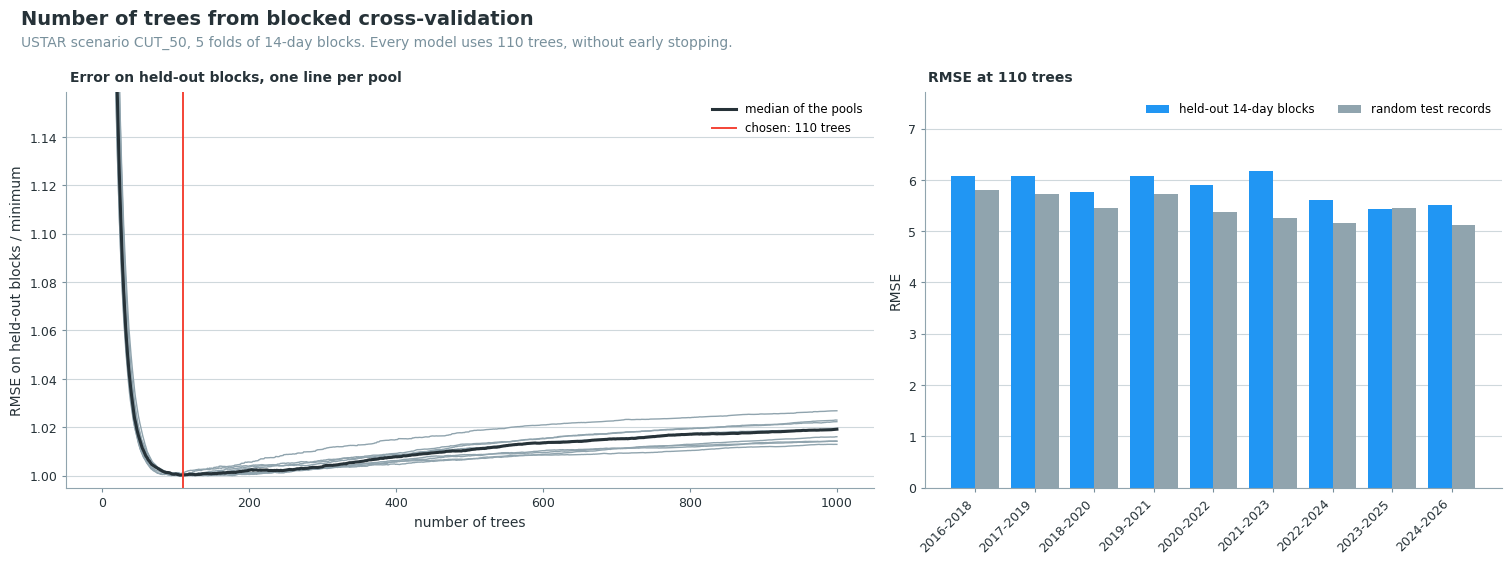

In [41]:
plot_tree_selection(data);

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [42]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
MDS       CUT_16   all    0.637   6.30   4.12    2.59   70.6
MDS       CUT_50   all    0.647   6.28   4.12    2.60   67.6
MDS       CUT_84   all    0.661   6.24   4.12    2.61   59.4
XGBoost   CUT_16   2016   0.783   4.83   3.30    2.18   37.8
XGBoost   CUT_16   2017   0.783   4.83   3.30    2.18   37.8
XGBoost   CUT_16   2018   0.779   4.87   3.33    2.23   41.8
XGBoost   CUT_16   2019   0.792   4.73   3.21    2.12   40.3
XGBoost   CUT_16   2020   0.795   4.84   3.27    2.13   43.9
XGBoost   CUT_16   2021   0.789   4.69   3.15    2.04   40.1
XGBoost   CUT_16   2022   0.788   4.68   3.16    2.06   42.1
XGBoost   CUT_16   2023   0.802   4.53   3.09    2.05   44.6
XGBoost   CUT_16   2024   0.817   4.53   3.06    2.00   37.5
XGBoost   CUT_16   2025   0.830   4.39   2.99    1.98   34.7
XGBoost   CUT_16   2026   0.830   4.39   2.99    1.98   34.7
XGBoost   CUT_16   mean   0.799   4.66   3.17    2.09   39.6
                                                            
XGBoost   CUT_50   2016   0.789   4.82   3.30    2.18   38.2
XGBoost   CUT_50   2017   0.789   4.82   3.30    2.18   38.2
XGBoost   CUT_50   2018   0.788   4.81   3.31    2.23   35.9
XGBoost   CUT_50   2019   0.802   4.65   3.18    2.11   40.0
XGBoost   CUT_50   2020   0.802   4.79   3.24    2.11   39.5
XGBoost   CUT_50   2021   0.797   4.64   3.13    2.03   41.3
XGBoost   CUT_50   2022   0.794   4.66   3.15    2.05   38.8
XGBoost   CUT_50   2023   0.810   4.50   3.07    2.03   41.6
XGBoost   CUT_50   2024   0.825   4.50   3.05    1.99   34.4
XGBoost   CUT_50   2025   0.836   4.36   2.98    1.95   38.1
XGBoost   CUT_50   2026   0.836   4.36   2.98    1.95   38.1
XGBoost   CUT_50   mean   0.806   4.63   3.15    2.08   38.6
                                                            
XGBoost   CUT_84   2016   0.799   4.76   3.27    2.18   36.3
XGBoost   CUT_84   2017   0.799   4.76   3.27    2.18   36.3
XGBoost   CUT_84   2018   0.799   4.73   3.27    2.22   34.7
XGBoost   CUT_84   2019   0.811   4.58   3.15    2.11   39.0
XGBoost   CUT_84   2020   0.811   4.72   3.22    2.12   40.1
XGBoost   CUT_84   2021   0.806   4.59   3.11    2.04   41.4
XGBoost   CUT_84   2022   0.801   4.64   3.14    2.04   40.6
XGBoost   CUT_84   2023   0.820   4.43   3.04    2.04   41.4
XGBoost   CUT_84   2024   0.834   4.45   3.03    2.01   35.6
XGBoost   CUT_84   2025   0.844   4.32   2.96    1.97   35.3
XGBoost   CUT_84   2026   0.844   4.32   2.96    1.97   35.3
XGBoost   CUT_84   mean   0.815   4.57   3.13    2.08   37.8
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [43]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2016         2016-2018              
2017         2016-2018              
2018         2017-2019              
2019         2018-2020              
2020         2019-2021              
2021         2020-2022              
2022         2021-2023              
2023         2022-2024              
2024         2023-2025              
2025         2024-2026              
2026         2024-2026              
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84) (does not pool years).

### 📋 Table: most important features (SHAP), CUT_16

In [44]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_16')

Feature importances, XGBoost (CUT_16): top 10 of 98 features, mean |SHAP|
 #   feature                            2016   2017   2018   2019   2020   2021   2022   2023   2024   2025   2026   mean
─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 2.74   2.74   3.11   3.32   3.40   2.72   2.39   3.78   3.65   4.01   4.01   3.26
 2   .DOY_COS                           1.56   1.56   1.93   1.76   1.29   0.71   0.85   1.32   1.82   1.74   1.74   1.48
 3   .SW_IN_T1_47_1_gfXG_MEAN2          1.58   1.58   1.39   0.78   0.52   0.87   1.50   0.46   0.46   0.46   0.46   0.91
 4   .HOUR_COS                          0.91   0.91   0.97   0.99   0.92   0.82   0.69   0.87   0.87   1.01   1.01   0.90
 5   .SW_IN_T1_47_1_gfXG_ROLLMAX2       0.08   0.08   0.19   0.48   0.93   1.14   0.98   0.97   1.37   0.72   0.72   0.69
 6   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.55   0.55   0.39   0.27   0.25   0.25   0.33   0.36   0.47   0.48   0.48   0.40
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.43   0.43   0.67   0.89   0.80   0.40   0.11   0.05   0.08   0.20   0.20   0.39
 8   .DOY_SIN                           0.26   0.26   0.34   0.25   0.23   0.11   0.34   0.48   0.27   0.28   0.28   0.28
 9   .WEEK_COS                          0.45   0.45   0.03   0.03   0.28   0.80   0.38   0.22   0.03   0.19   0.19   0.28
10   .SW_IN_T1_47_1_gfXG_ROLLMIN2       0.15   0.15   0.07   0.31   0.11   0.19   0.05   0.38   0.37   0.37   0.37   0.23

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_16) (no model trained).

### 📋 Table: most important features (SHAP), CUT_50

In [45]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_50')

Feature importances, XGBoost (CUT_50): top 10 of 98 features, mean |SHAP|
 #   feature                            2016   2017   2018   2019   2020   2021   2022   2023   2024   2025   2026   mean
─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 2.62   2.62   3.05   3.14   3.14   2.83   2.76   3.64   3.78   3.99   3.99   3.23
 2   .DOY_COS                           1.52   1.52   1.85   1.81   1.19   0.77   0.84   1.22   1.91   1.76   1.76   1.47
 3   .SW_IN_T1_47_1_gfXG_MEAN2          1.69   1.69   1.56   1.17   1.47   1.04   1.49   0.30   0.85   0.31   0.31   1.08
 4   .HOUR_COS                          0.91   0.91   0.93   0.96   0.92   0.79   0.69   0.82   0.88   1.04   1.04   0.90
 5   .SW_IN_T1_47_1_gfXG_ROLLMAX2       0.06   0.06   0.19   0.34   0.52   0.93   0.90   1.14   0.82   0.85   0.85   0.61
 6   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.50   0.50   0.38   0.29   0.18   0.28   0.32   0.35   0.51   0.42   0.42   0.38
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.45   0.45   0.69   0.69   0.53   0.26   0.18   0.07   0.12   0.17   0.17   0.34
 8   .SW_IN_T1_47_1_gfXG_ROLLMIN2       0.13   0.13   0.11   0.57   0.17   0.21   0.07   0.62   0.49   0.52   0.52   0.32
 9   .DOY_SIN                           0.29   0.29   0.39   0.30   0.21   0.16   0.35   0.43   0.34   0.28   0.28   0.30
10   .WEEK_COS                          0.52   0.52   0.01   0.06   0.39   0.74   0.31   0.23   0.05   0.15   0.15   0.28

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_50) (no model trained).

### 📋 Table: most important features (SHAP), CUT_84

In [46]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_84')

Feature importances, XGBoost (CUT_84): top 10 of 98 features, mean |SHAP|
 #   feature                            2016   2017   2018   2019   2020   2021   2022   2023   2024   2025   2026   mean
─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 3.04   3.04   3.55   3.31   3.18   2.98   2.60   3.44   3.71   4.13   4.13   3.37
 2   .DOY_COS                           1.52   1.52   2.04   2.00   1.39   0.73   0.89   1.30   1.98   1.74   1.74   1.53
 3   .SW_IN_T1_47_1_gfXG_MEAN2          1.52   1.52   1.56   1.39   1.49   1.26   2.03   1.07   0.78   0.37   0.37   1.22
 4   .HOUR_COS                          0.87   0.87   0.94   0.94   0.93   0.86   0.70   0.77   0.84   1.01   1.01   0.88
 5   .SW_IN_T1_47_1_gfXG_ROLLMAX2       0.06   0.06   0.06   0.18   0.45   0.65   0.53   0.64   1.23   0.97   0.97   0.53
 6   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.53   0.53   0.41   0.29   0.11   0.23   0.27   0.42   0.45   0.42   0.42   0.37
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.52   0.52   0.64   0.58   0.54   0.28   0.11   0.04   0.16   0.33   0.33   0.37
 8   .DOY_SIN                           0.37   0.37   0.46   0.34   0.25   0.24   0.33   0.46   0.32   0.32   0.32   0.34
 9   .WEEK_COS                          0.70   0.70   0.02   0.03   0.29   0.70   0.27   0.21   0.03   0.19   0.19   0.30
10   .SW_IN_T1_47_1_gfXG_ROLLMIN2       0.14   0.14   0.03   0.51   0.39   0.30   0.04   0.41   0.41   0.43   0.43   0.29

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_84) (no model trained).

### 📊 Plot: feature ranks per year

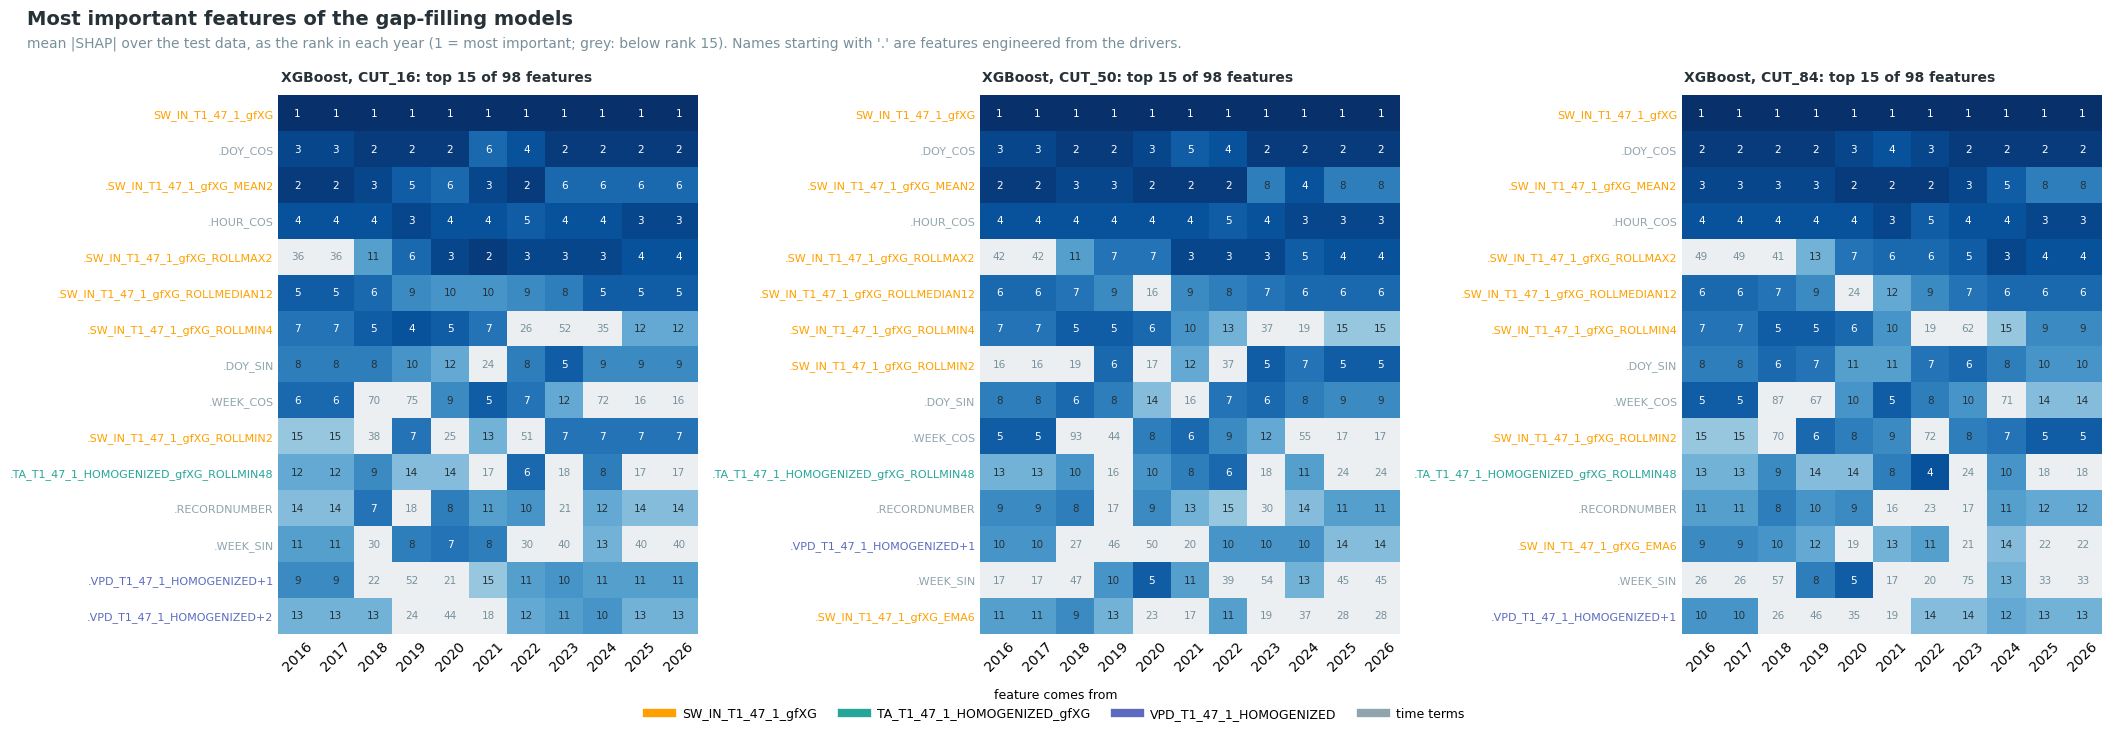

In [47]:
plot_feature_ranks_per_year(data)

## Step 11: result plots

### 📊 Plot: flux by quality class, heatmaps, XGBoost, CUT_50

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

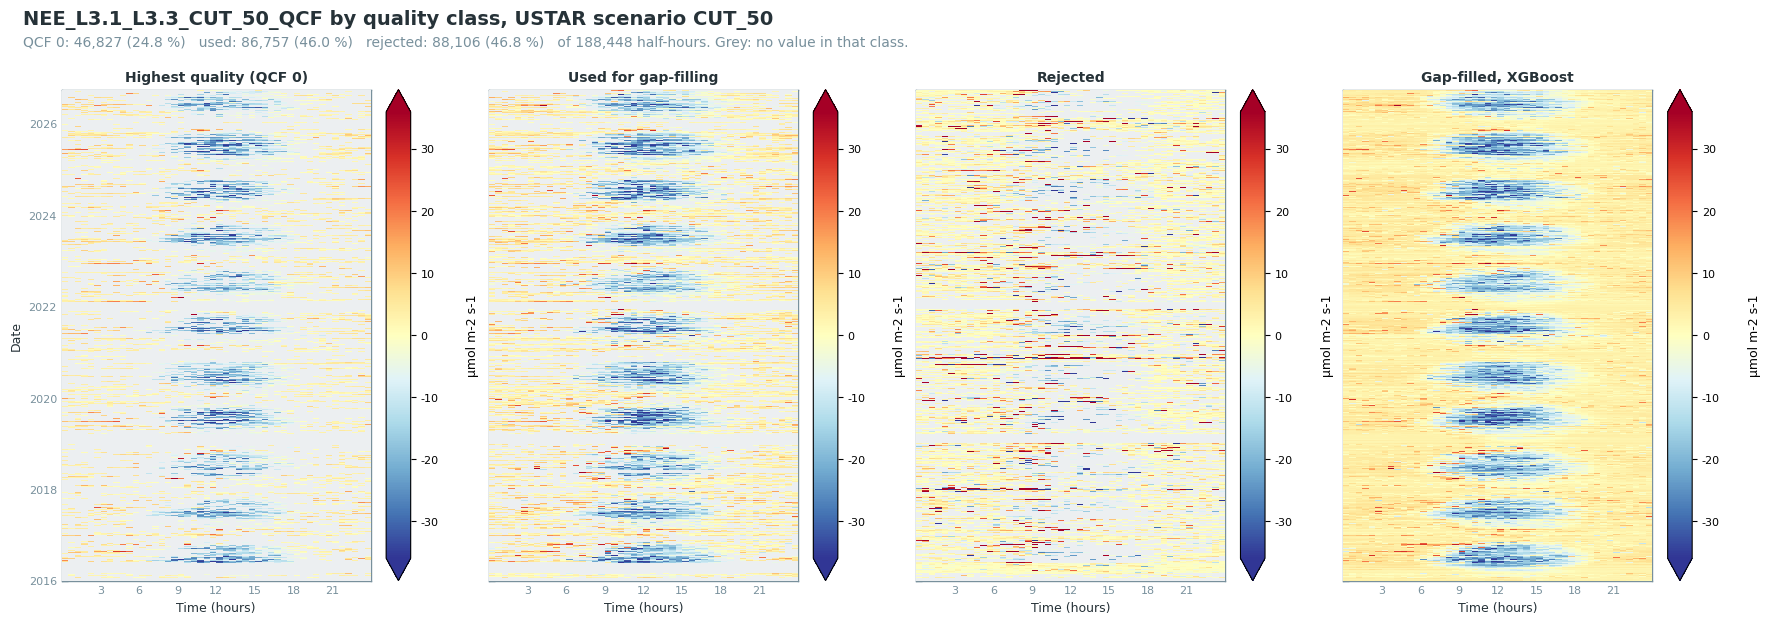

In [48]:
plot_quality_heatmaps(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: flux by quality class, day and night, XGBoost, CUT_50

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

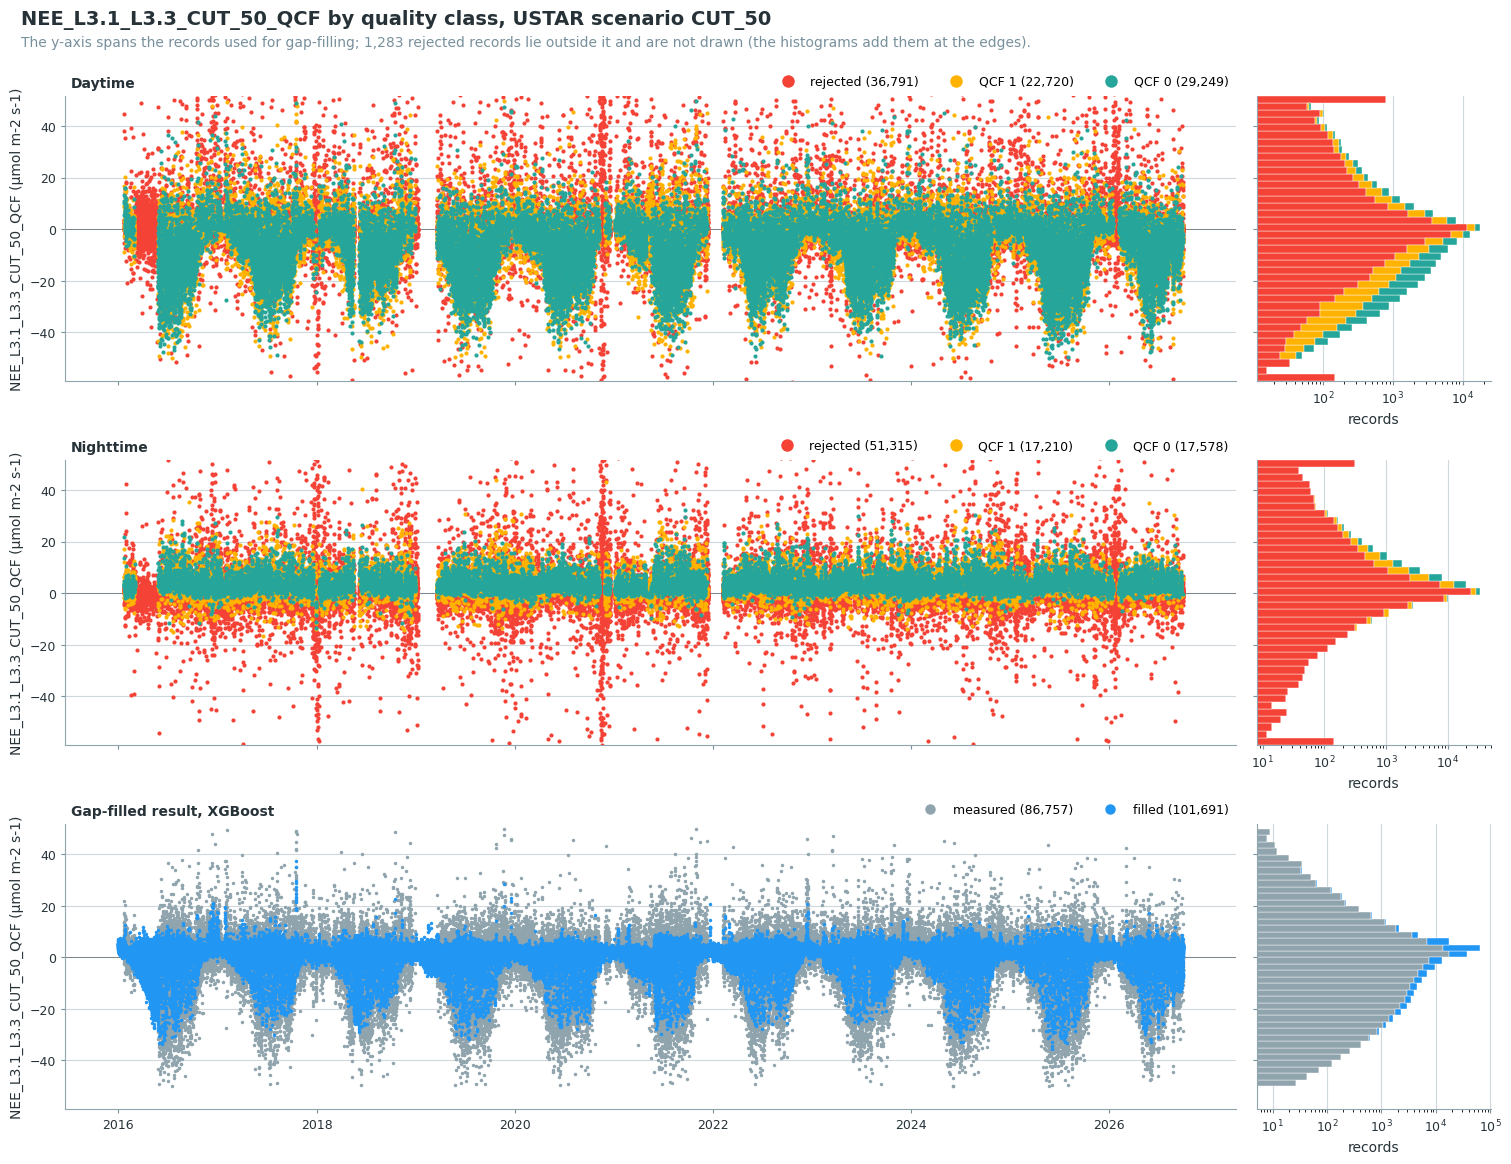

In [49]:
plot_quality_timeseries(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled flux, CUT_50

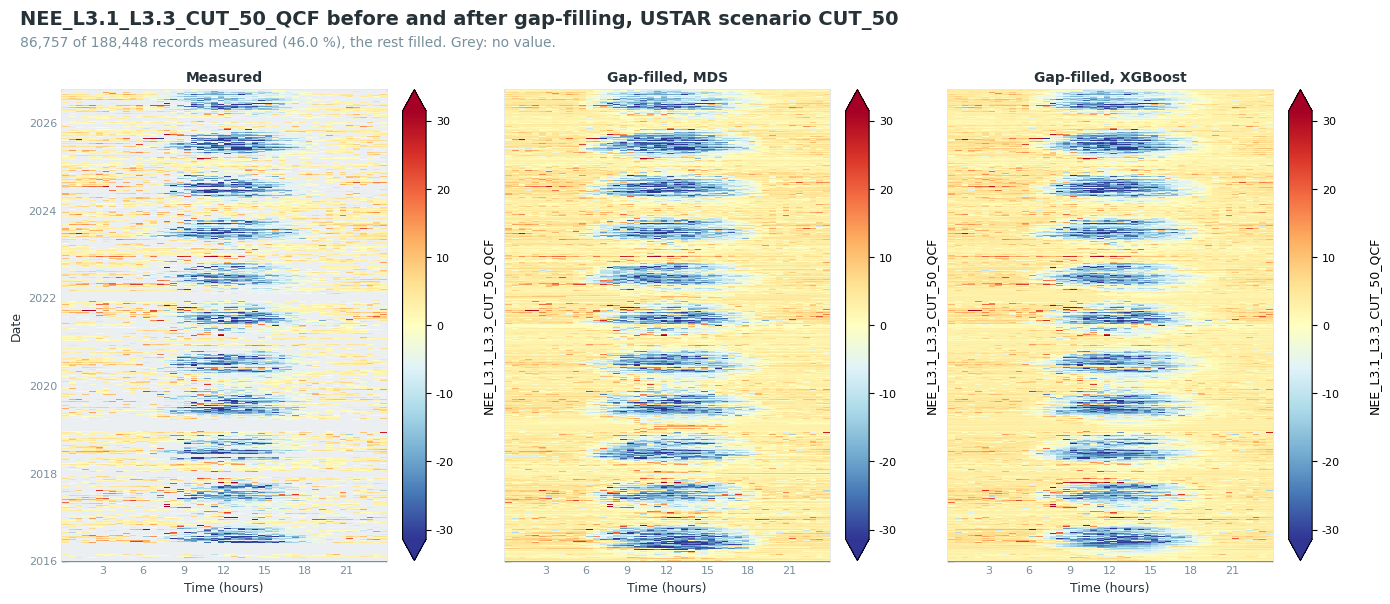

In [50]:
data.plot_gapfilled_heatmaps(ustar_scenario='CUT_50')

### 📊 Plot: cumulative flux, CUT_50

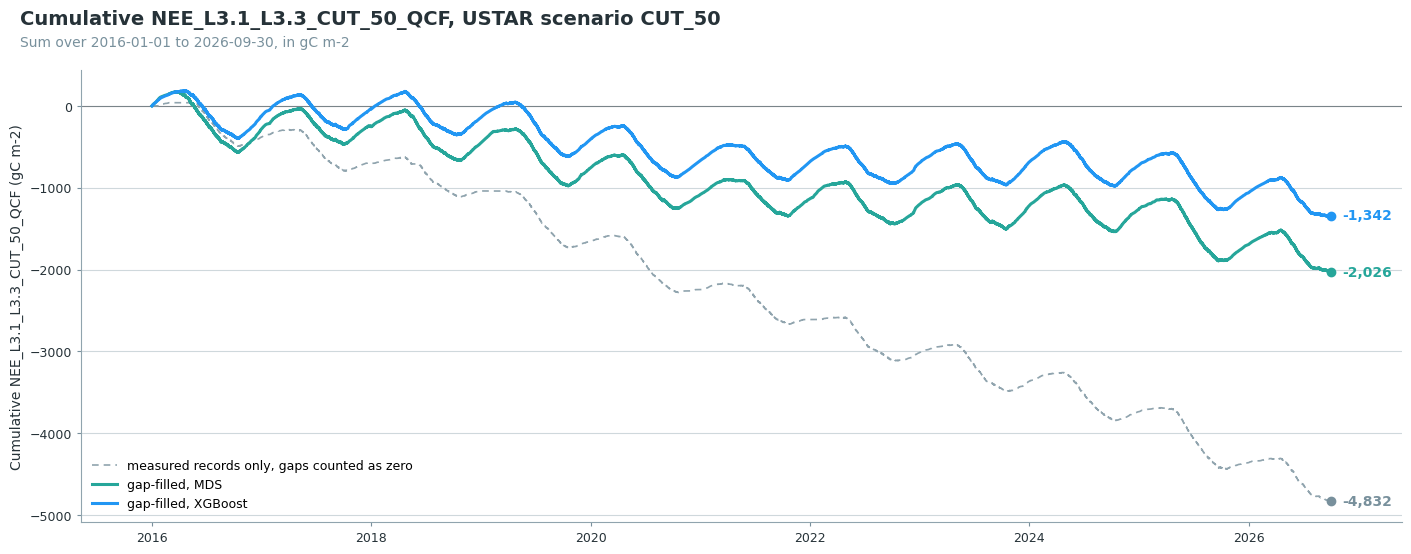

In [51]:
data.plot_cumulative_comparison(
    ustar_scenario='CUT_50',
    conv_factor=UMOL_TO_GC,
    units='gC m-2',
)

### 📊 Plot: cumulative flux of all USTAR scenarios

One line per gap-filling method and USTAR scenario, each method in its own colour. The spread
between CUT_16, CUT_50 and CUT_84 shows how much the annual sum depends on the USTAR threshold. It also contains the variation of the gap-filling model, which
changes with the records each scenario keeps.

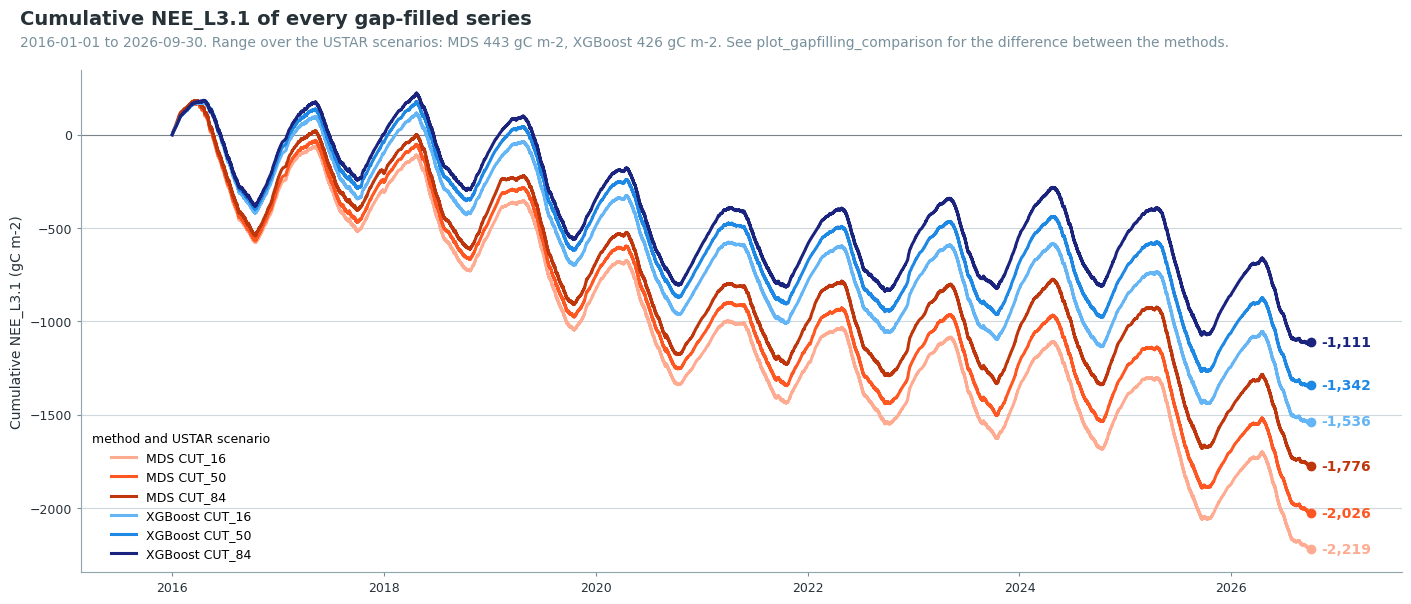

In [52]:
plot_gapfilled_cumulative(
    data,
    gain=UMOL_TO_GC,
    units='gC m-2',
    per_year=False,
)

### 📊 Plot: cumulative flux per year, for each scenario

One line per year; the band is the mean ± 1 SD of the full years. An incomplete last year is left
out of the band.

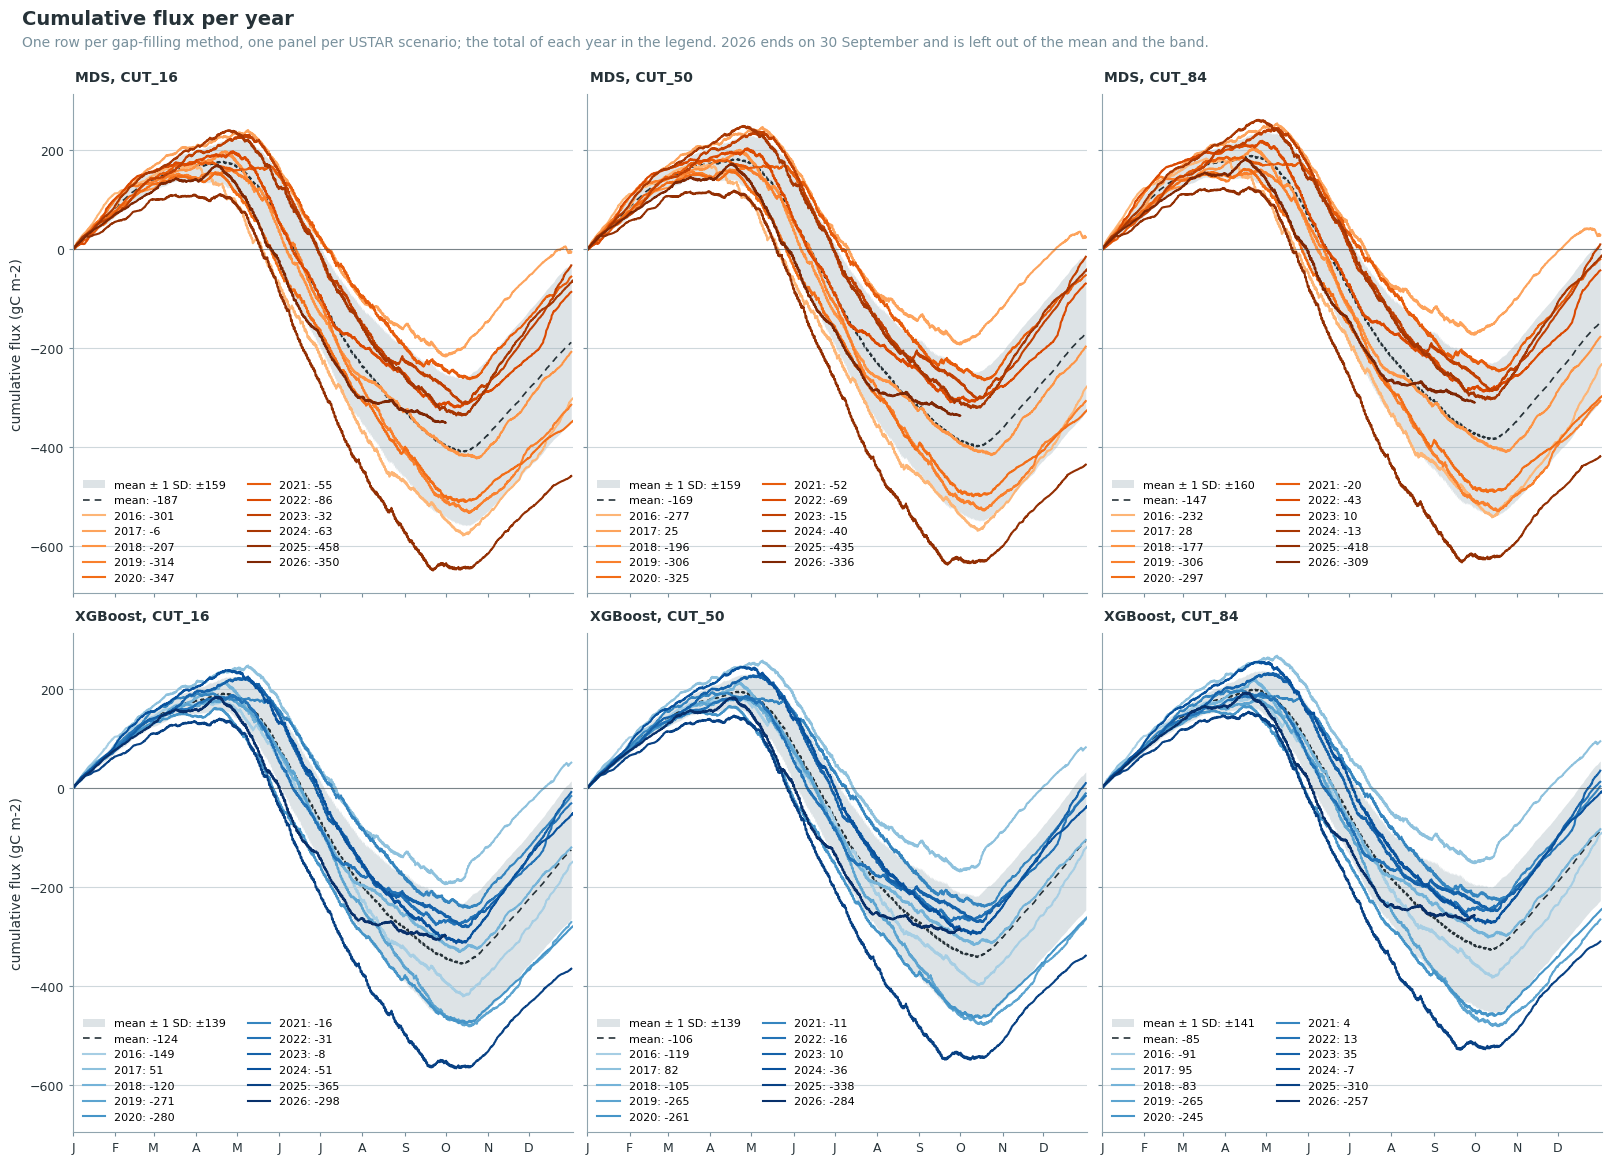

In [53]:
# One row per gap-filling method, one panel per USTAR scenario, on a shared y-axis. Years run
# from light to dark, so the most recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(len(_gf), len(USTAR_SCENARIOS), figsize=(16, 5.5 * len(_gf) + 0.6),
                         sharex=True, sharey=True, layout='constrained', squeeze=False)
for _row, (_method, _cols) in zip(axes, _gf.items()):
    for _ax, _scen in zip(_row, USTAR_SCENARIOS):
        _cum = doy_cumulatives_per_year(data.fpc_df[_cols[_scen]] * UMOL_TO_GC)
        _cum = _cum.loc[:, _cum.notna().any()]
        _years = list(_cum.columns)
        _shades = plt.get_cmap(cp.METHOD_CMAPS.get(_method, 'Greys'))(
            np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
        if len(_years) > 1:
            _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                       excl_years_from_reference=_partial)
            # Day 366 exists only in leap years, so the band stops before it.
            _ref = _ref.loc[_ref.index < 366]
            # The legend gives the mean and SD of the annual totals of the full years.
            _totals = [_cum[_y].dropna().iloc[-1] for _y in _years if _y not in (_partial or [])]
            _end_mean, _end_sd = np.mean(_totals), np.std(_totals, ddof=1)
            _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color=cp.KEPT,
                             alpha=0.3, linewidth=0, label=f'mean ± 1 SD: ±{_end_sd:,.0f}')
            _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color=cp.INK, linewidth=1.2,
                     linestyle=(0, (4, 3)), label=f'mean: {_end_mean:,.0f}')
        for _shade, _year in zip(_shades, _years):
            _valid = _cum[_year].dropna()
            _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                     label=f"{_year}: {_valid.iloc[-1]:,.0f}")
        _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        cp.style_axes(_ax)
        cp.panel_label(_ax, f"{_names.get(_method, _method)}, {_scen}")
        _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
        _ax.set_xlim(1, 367)
        _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2)
    _row[0].set_ylabel('cumulative flux (gC m-2)')
_subtitle = ("One row per gap-filling method, one panel per USTAR scenario; the total of each "
             "year in the legend.")
if _partial:
    _subtitle += f" {_end.year} ends on {_end:%d %B} and is left out of the mean and the band."
cp.figure_title(fig, 'Cumulative flux per year', _subtitle)
plt.show()

### Gap-filling methods compared

The difference between the sums of MDS and XGBoost comes from the filled gaps alone; the table
splits it by day and night and by gap length ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#method-comparison)).

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [54]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=UMOL_TO_GC, units='gC m-2');

Gap-filling methods compared: MDS and XGBoost
            sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR       MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
───────────────────────────────────────────────────────────────────────────────────────────
CUT_16   -2,219    -1,536          683        631           53     21    222     209    232
CUT_50   -2,026    -1,342          685        666           19      8    202     250    224
CUT_84   -1,776    -1,111          666        711          -46     -2    169     309    189
Sums (gC m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_16, same 22,991 held-out records: MDS R² 0.64 RMSE 6.31, XGBoost R² 0.73 RMSE 5.45
CUT_50, same 21,629 held-out records: MDS R² 0.65 RMSE 6.21, XGBoost R² 0.73 RMSE 5.42
CUT_84, same 20,064 held-out records: MDS R² 0.67 RMSE 6.23, XGBoost R² 0.75 RMSE 5.35
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference for every
USTAR scenario.

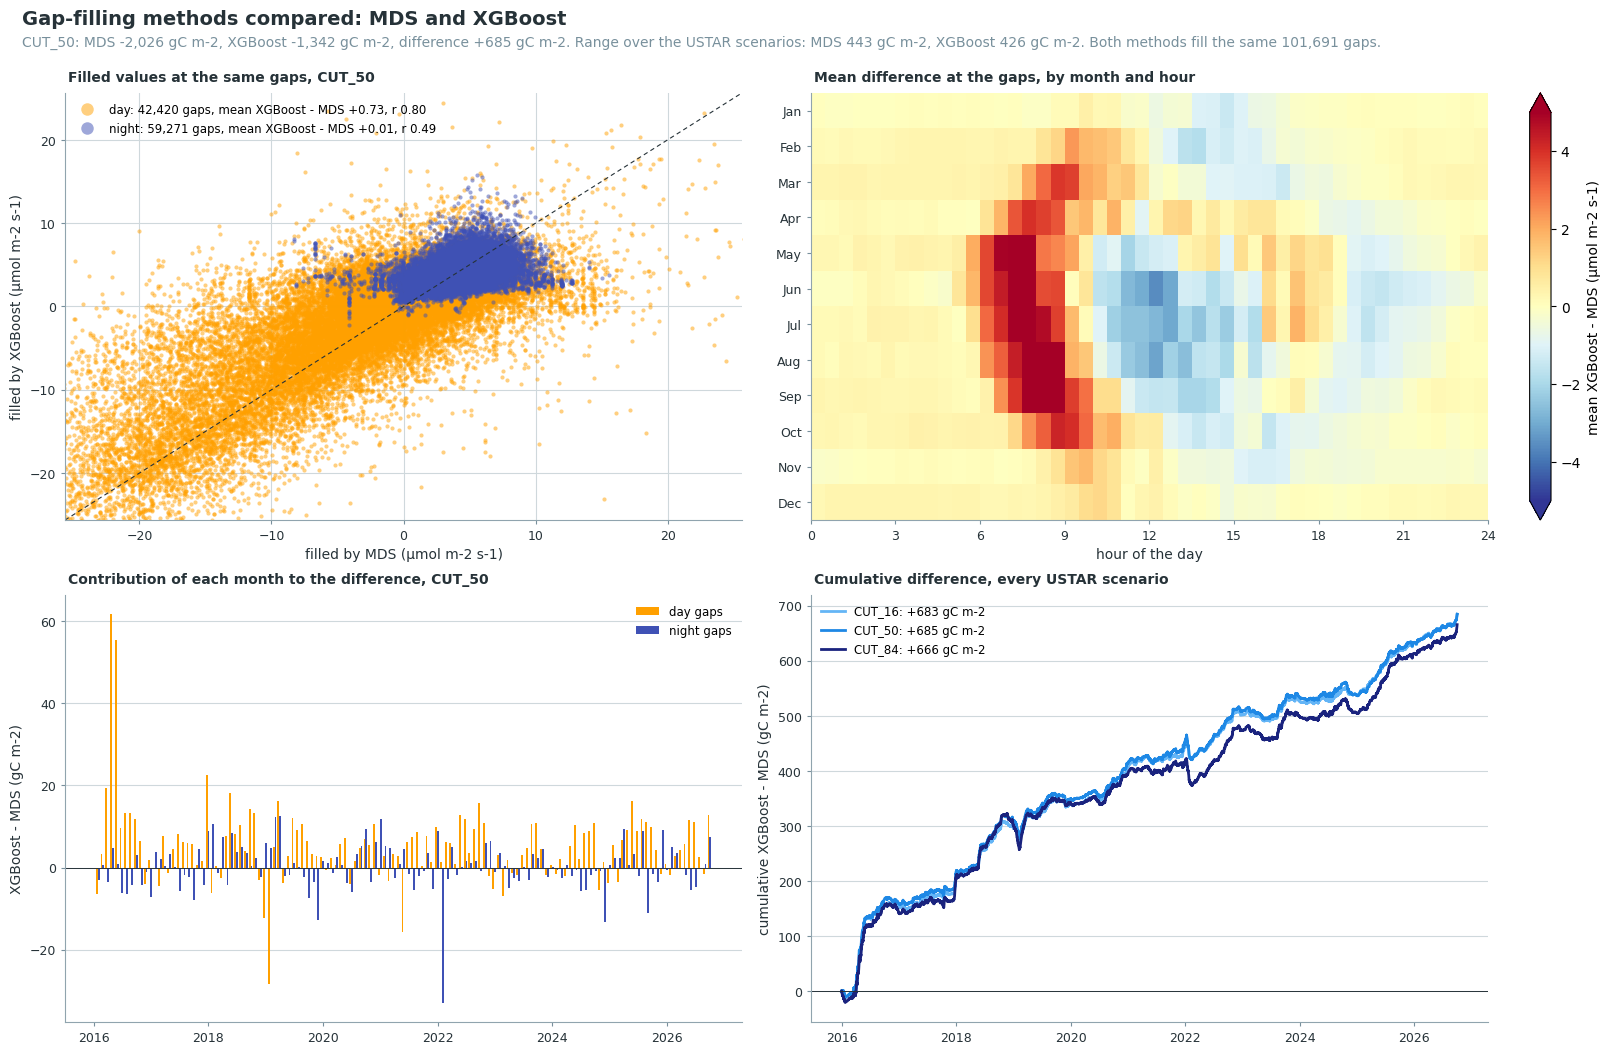

In [55]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario='CUT_50', methods=('mds', 'xgb'),
                               gain=UMOL_TO_GC, units='gC m-2', flux_units=FLUX_UNITS);

## Step 12: uncertainty

Random, USTAR and joint uncertainty of the `UNC_REF` (CUT_50) series of each method, after
Pastorello et al. (2020), at 1 sigma in flux units. In sums the random part adds in quadrature and
the USTAR part as half the difference between the CUT_84 and CUT_16 sums; the difference between
the methods is reported beside them ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#uncertainty)).

### 📋 Table: random uncertainty, records per method

In [56]:
METHOD_NAMES = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
METHOD_COLORS = {_k: _v[1] for _k, _v in cp.METHOD_COLORS.items()}  # the hue of each method
GF_COLS = data.gapfilled_cols()  # {method: {USTAR scenario: gap-filled column}}
_m = data.merged_df(verbose=0)

RANDUNC = {}
for _method, _cols in GF_COLS.items():
    print(f"\n{METHOD_NAMES.get(_method, _method)}, {UNC_REF}")
    RANDUNC[_method] = dv.flux.RandomUncertaintyPAS20(
        df=_m,
        fluxcol=data.nongapfilled_cols()[_method][UNC_REF],
        fluxgapfilledcol=_cols[UNC_REF],
        tacol=TA_F,
        vpdcol=VPD_F,  # kPa
        swincol=SW_IN_F,
        vpd_in_kpa=True,
    )
    RANDUNC[_method].run()
    RANDUNC[_method].report_method_summary()


MDS, CUT_50


> Calculating random uncertainty with window size +/-7 days and +/-1 hours (method 1) ...

> Time needed: 5.70s

> Calculating random uncertainty with window size +/-14 days (method 2) ...

> Time needed: 7.54s

...

METHOD DISTRIBUTION:

Method  Records Percentage
1: Sliding Window (+/-7d, +/-1h) [ONEFlux]    55170      29.3%
 2: Similar Flux Median (+/-14d) [ONEFlux]   125766      66.7%
3: Similar Flux Median (no window)      7512       4.0%
                 4: Nearest Fluxes         0       0.0%

UNCERTAINTY STATISTICS (umol CO2 m-2 s-1):

Statistic Value (umol CO2 m-2 s-1)
     Mean                   3.7678
  Std Dev                   1.8862
      Min                   0.2252
      Max                  25.9764
    Range                  25.7512

================================================================================

### 📋 Table: random, USTAR and joint uncertainty per record

In [57]:
# Per method, the three columns written to the output file. The USTAR term is stored as a
# magnitude: CUT_84 is not always above CUT_16, and the joint uncertainty uses its square.
UNC = {}
for _method, _cols in GF_COLS.items():
    _gf = _cols[UNC_REF]
    _joint = dv.flux.JointUncertaintyPAS20(
        df=pd.DataFrame({f'{_gf}_RANDUNC': RANDUNC[_method].randunc_series,
                         'lower': _m[_cols[UNC_LOWER]],
                         'upper': _m[_cols[UNC_UPPER]]}),
        randunccol=f'{_gf}_RANDUNC',
        scenario_lower_col='lower',
        scenario_upper_col='upper',
        name=f'{_gf}_JOINTUNC',
    )
    _joint.run()
    print(f"\n{METHOD_NAMES.get(_method, _method)}, {UNC_REF}")
    _joint.report_summary()
    _res = _joint.jointunc_results.rename(columns={_joint.scenarionunccol: f'{_gf}_USTARUNC'})
    _res[f'{_gf}_USTARUNC'] = _res[f'{_gf}_USTARUNC'].abs()
    UNC[_method] = _res[[f'{_gf}_RANDUNC', f'{_gf}_USTARUNC', f'{_gf}_JOINTUNC']]
    assert UNC[_method].notna().all().all(), f"a record of {_gf} has no uncertainty"
UNC_EXPORT = pd.concat(UNC.values(), axis=1)

# The flux and its uncertainty of each method in gC m-2 per half-hour, the input of the sums below.
UNC_FRAMES = {
    _method: pd.DataFrame({
        'flux': _m[_cols[UNC_REF]] * UMOL_TO_GC,
        'var': (UNC[_method][f'{_cols[UNC_REF]}_RANDUNC'] * UMOL_TO_GC) ** 2,
        'lower': _m[_cols[UNC_LOWER]] * UMOL_TO_GC,
        'upper': _m[_cols[UNC_UPPER]] * UMOL_TO_GC,
    })
    for _method, _cols in GF_COLS.items()
}


def period_sums(frame, freq):
    """Sums per period and their 1-sigma uncertainty: the random part in quadrature, the USTAR
    part as half the spread of the CUT_84 and CUT_16 sums."""
    s = frame.resample(freq).sum()
    out = pd.DataFrame({'sum': s['flux'], 'random': np.sqrt(s['var']),
                        'USTAR': ((s['upper'] - s['lower']) / 2).abs()})
    out['joint'] = np.sqrt(out['random'] ** 2 + out['USTAR'] ** 2)
    return out


MDS, CUT_50


================================================================================

JOINT UNCERTAINTY (PAS20) SUMMARY

================================================================================

Output column: NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_JOINTUNC  |  records with estimate: 188,448

...

Output column: NEE_L3.1_L3.3_CUT_50_QCF_gfXG_JOINTUNC  |  records with estimate: 188,448

random term      mean: 3.7678  median: 3.3027

scenario term    mean: 0.0522  median: 0.0000

joint            mean: 3.8247  median: 3.3496

================================================================================

### 📋 Table: annual sums with their uncertainty

`random`, `USTAR` and `joint` are 1-sigma uncertainties of the annual sum of each method. The
second table gives the difference between the methods, which is reported beside the joint
uncertainty and not included in it. An incomplete last year covers only part of it.

In [58]:
ANNUAL_UNC = {_method: period_sums(_f, 'YS').rename(index=lambda _t: _t.year)
              for _method, _f in UNC_FRAMES.items()}
print(f"Annual sums of the {UNC_REF} series and their uncertainty (gC m-2, 1 sigma)")
display(pd.concat({METHOD_NAMES.get(_k, _k): _v for _k, _v in ANNUAL_UNC.items()},
                  names=['method', 'year']).round(1))

if len(ANNUAL_UNC) > 1:
    _names = [METHOD_NAMES.get(_k, _k) for _k in ANNUAL_UNC]
    _s = pd.DataFrame({_n: _v['sum'] for _n, _v in zip(_names, ANNUAL_UNC.values())})
    _diff = pd.DataFrame({f'{_b} - {_a}': _s[_b] - _s[_a]
                          for _i, _a in enumerate(_names) for _b in _names[_i + 1:]})
    _diff.index.name = 'year'
    print(f"\nDifference between the methods (gC m-2), not part of the joint uncertainty")
    display(_diff.round(1))

Annual sums of the CUT_50 series and their uncertainty (gC m-2, 1 sigma)


sum  random  USTAR  joint
method  year                             
MDS     2016 -276.7    13.2   34.6   37.1
        2017   24.6    12.7   17.0   21.3
        2018 -196.4    13.0   15.1   19.9
        2019 -306.3    12.4    3.9   13.0
        2020 -324.8    11.0   25.0   27.3
        2021  -52.1    13.3   17.6   22.0
        2022  -69.0    11.2   21.7   24.4
        2023  -15.0    12.1   21.2   24.4
        2024  -39.9    12.5   25.2   28.2
        2025 -434.8    11.5   19.9   22.9
        2026 -335.9     9.1   20.4   22.4
XGBoost 2016 -118.6    13.0   29.1   31.9
        2017   82.3    12.7   21.6   25.0
        2018 -104.6    12.8   18.4   22.4
        2019 -264.8    12.3    2.6   12.6
        2020 -260.8    10.8   17.5   20.6
        2021  -10.6    13.1    9.7   16.4
        2022  -15.8    11.0   21.7   24.4
        2023   10.1    12.0   21.6   24.7
        2024  -36.3    12.4   22.3   25.5
        2025 -338.4    11.4   27.6   29.8
        2026 -284.4     9.0   20.5   22.4


Difference between the methods (gC m-2), not part of the joint uncertainty


,XGBoost - MDS
year,
2016,158.1
2017,57.8
2018,91.8
2019,41.6
2020,64.0
2021,41.6
2022,53.2
2023,25.1
2024,3.6


### 📊 Plot: annual sums with their uncertainty

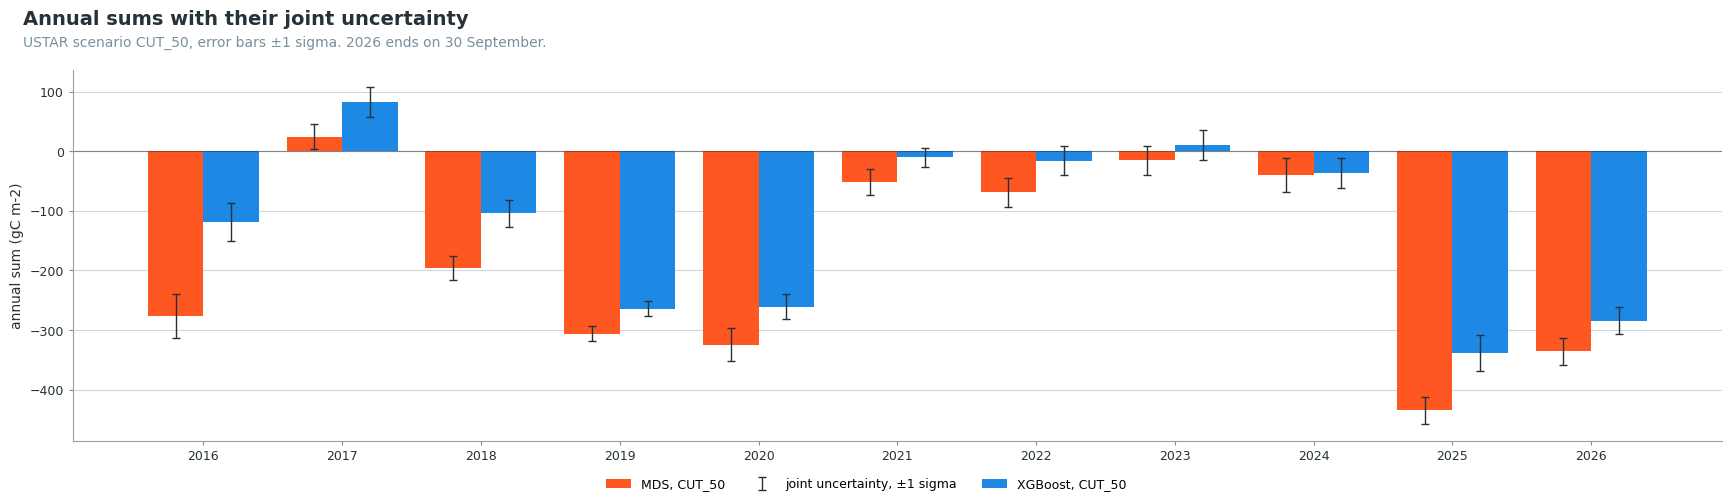

In [59]:
_methods = list(ANNUAL_UNC)
_years = ANNUAL_UNC[_methods[0]].index
_width = 0.8 / len(_methods)
_end = _m.index[-1]
fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(_years) + 4), 5), layout='constrained')
for _i, _method in enumerate(_methods):
    _a = ANNUAL_UNC[_method]
    _x = np.arange(len(_years)) + (_i - (len(_methods) - 1) / 2) * _width
    ax.bar(_x, _a['sum'], _width, color=METHOD_COLORS.get(_method, cp.KEPT),
           label=f'{METHOD_NAMES.get(_method, _method)}, {UNC_REF}')
    ax.errorbar(_x, _a['sum'], yerr=_a['joint'], fmt='none', ecolor=cp.INK, capsize=3,
                linewidth=1, label='joint uncertainty, ±1 sigma' if _i == 0 else None)
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_xticks(np.arange(len(_years)), _years)
ax.set_ylabel('annual sum (gC m-2)')
cp.style_axes(ax)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(_methods) + 1, fontsize=9)
cp.figure_title(fig, 'Annual sums with their joint uncertainty',
                f"USTAR scenario {UNC_REF}, error bars ±1 sigma."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

### 📊 Plot: cumulative flux per year with its uncertainty

One panel per year, one line and band per gap-filling method. The band is the joint uncertainty,
accumulated from 1 January: the random part in quadrature, the USTAR part as half the spread of
the cumulative CUT_84 and CUT_16 sums. Where the bands of two methods do not overlap, the methods
differ by more than the joint uncertainty.

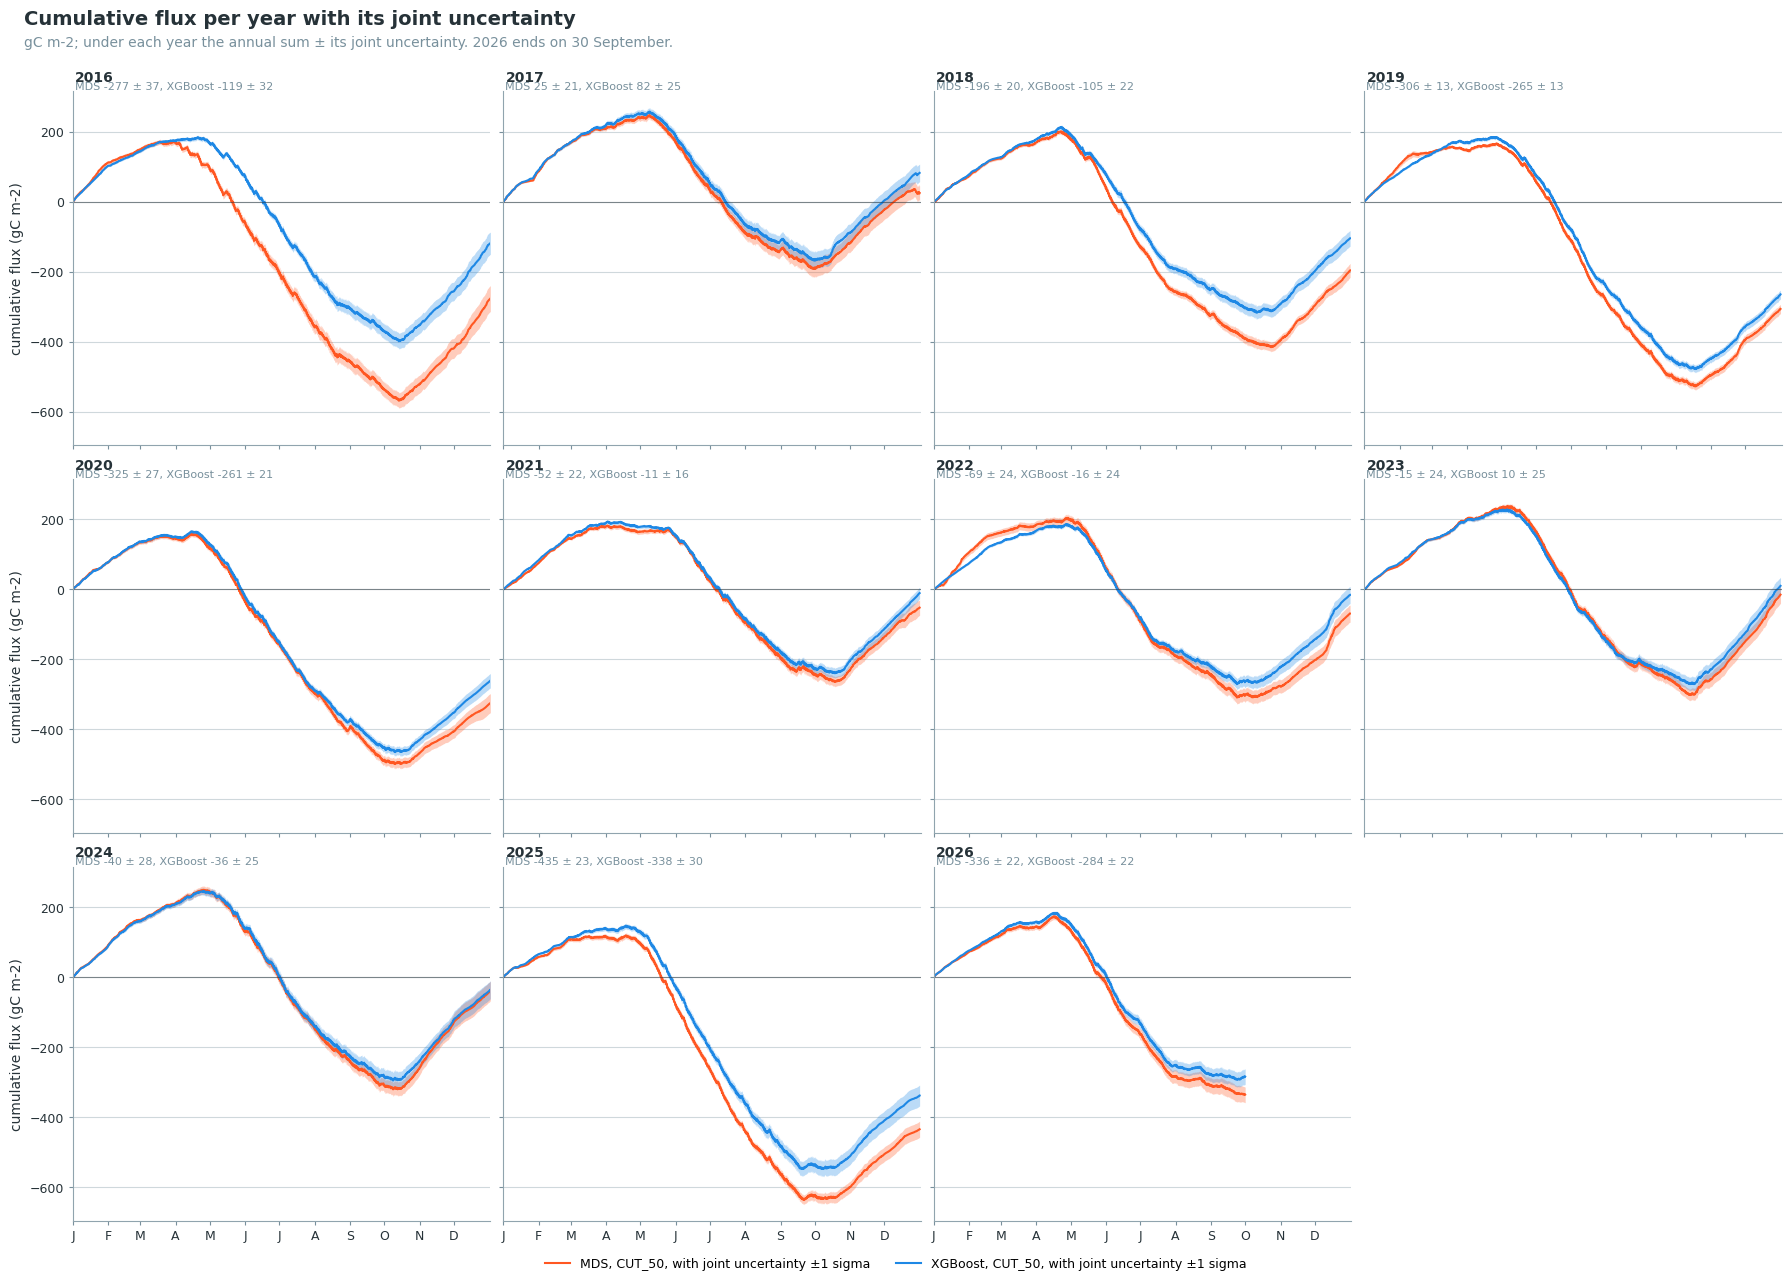

In [60]:
_years = sorted(set(_m.index.year))
_end = _m.index[-1]
_ncol = min(4, len(_years))
_nrow = -(-len(_years) // _ncol)
_month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
fig, axes = plt.subplots(_nrow, _ncol, figsize=(4.2 * _ncol + 1, 3.8 * _nrow + 1.4), sharex=True,
                         sharey=True, layout='constrained', squeeze=False)
for _ax, _year in zip(axes.flat, _years):
    _totals = []
    for _method, _f in UNC_FRAMES.items():
        _d = _f.loc[str(_year)]
        _doy = (_d.index.dayofyear + (_d.index.hour + _d.index.minute / 60) / 24).to_numpy()
        _cum = _d['flux'].cumsum()
        _joint = np.sqrt(_d['var'].cumsum()
                         + ((_d['upper'].cumsum() - _d['lower'].cumsum()) / 2) ** 2)
        _color = METHOD_COLORS.get(_method, cp.KEPT)
        _name = METHOD_NAMES.get(_method, _method)
        _ax.fill_between(_doy, _cum - _joint, _cum + _joint, color=_color, alpha=0.3,
                         linewidth=0)
        _ax.plot(_doy, _cum, color=_color, linewidth=1.5,
                 label=f'{_name}, {UNC_REF}, with joint uncertainty ±1 sigma')
        _totals.append(f"{_name} {_cum.iloc[-1]:,.0f} ± {_joint.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, f"{_year}")
    _ax.text(0.005, 1.0, ", ".join(_totals), transform=_ax.transAxes, ha='left', va='bottom',
             fontsize=8, color=cp.MUTED)
    _ax.set_xticks(_month_starts, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
for _ax in axes.flat[len(_years):]:
    _ax.set_visible(False)
for _row in axes:
    _row[0].set_ylabel('cumulative flux (gC m-2)')
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(UNC_FRAMES), fontsize=9)
cp.figure_title(fig, 'Cumulative flux per year with its joint uncertainty',
                "gC m-2; under each year the annual sum ± its joint uncertainty."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

### 📊 Plot: daily sums with their uncertainty

Two panels per gap-filling method: the daily sum with its joint uncertainty, then the uncertainty
of the daily sums and its two parts.

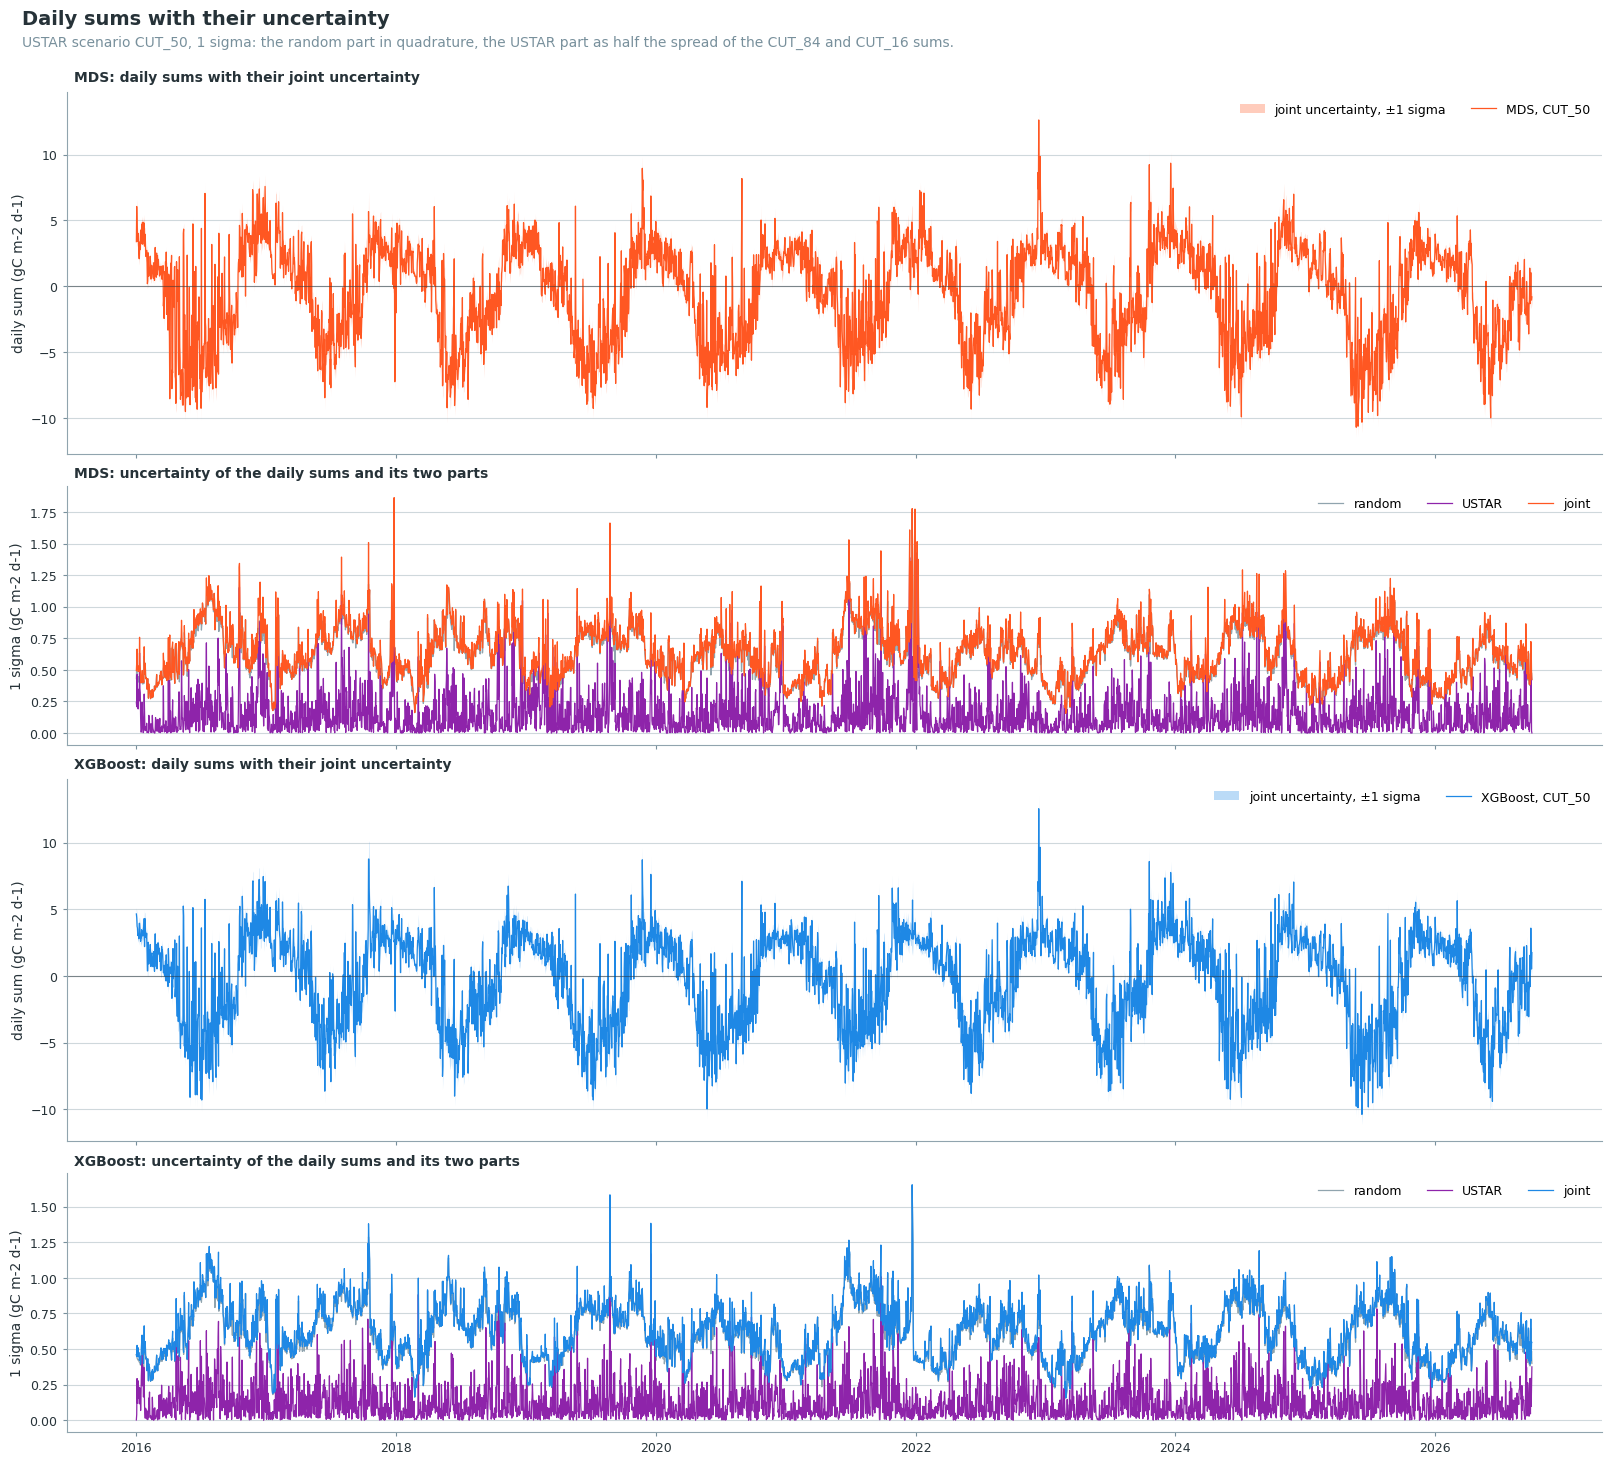

In [61]:
_methods = list(UNC_FRAMES)
fig, axs = plt.subplots(2 * len(_methods), 1, figsize=(16, 7 * len(_methods) + 0.6), sharex=True,
                        layout='constrained', height_ratios=[1.4, 1] * len(_methods))
for _i, _method in enumerate(_methods):
    _day = period_sums(UNC_FRAMES[_method], 'D')
    _color = METHOD_COLORS.get(_method, cp.KEPT)
    _name = METHOD_NAMES.get(_method, _method)
    _top, _bottom = axs[2 * _i], axs[2 * _i + 1]
    _top.fill_between(_day.index, _day['sum'] - _day['joint'], _day['sum'] + _day['joint'],
                      color=_color, alpha=0.3, linewidth=0, label='joint uncertainty, ±1 sigma')
    _top.plot(_day.index, _day['sum'], color=_color, linewidth=0.9, label=f'{_name}, {UNC_REF}')
    _top.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _top.set_ylabel('daily sum (gC m-2 d-1)')
    cp.panel_label(_top, f'{_name}: daily sums with their joint uncertainty')
    for _col, _c in (('random', cp.KEPT), ('USTAR', cp.TEST_COLORS[2]), ('joint', _color)):
        _bottom.plot(_day.index, _day[_col], color=_c, linewidth=0.9, label=_col)
    _bottom.set_ylabel('1 sigma (gC m-2 d-1)')
    cp.panel_label(_bottom, f'{_name}: uncertainty of the daily sums and its two parts')
for _ax in axs:
    cp.style_axes(_ax)
    _ax.legend(frameon=False, fontsize=9, loc='upper right', ncol=3)
cp.figure_title(fig, 'Daily sums with their uncertainty',
                f"USTAR scenario {UNC_REF}, 1 sigma: the random part in quadrature, the USTAR part "
                f"as half the spread of the {UNC_UPPER} and {UNC_LOWER} sums.")
plt.show()

### 📊 Plot: heatmaps of the flux and its uncertainty

One row per gap-filling method, date against time of day. The random uncertainty grows with the
size of the flux. The USTAR uncertainty is zero where all three scenarios keep the measured
record, and appears only where a record was removed in one scenario and filled.

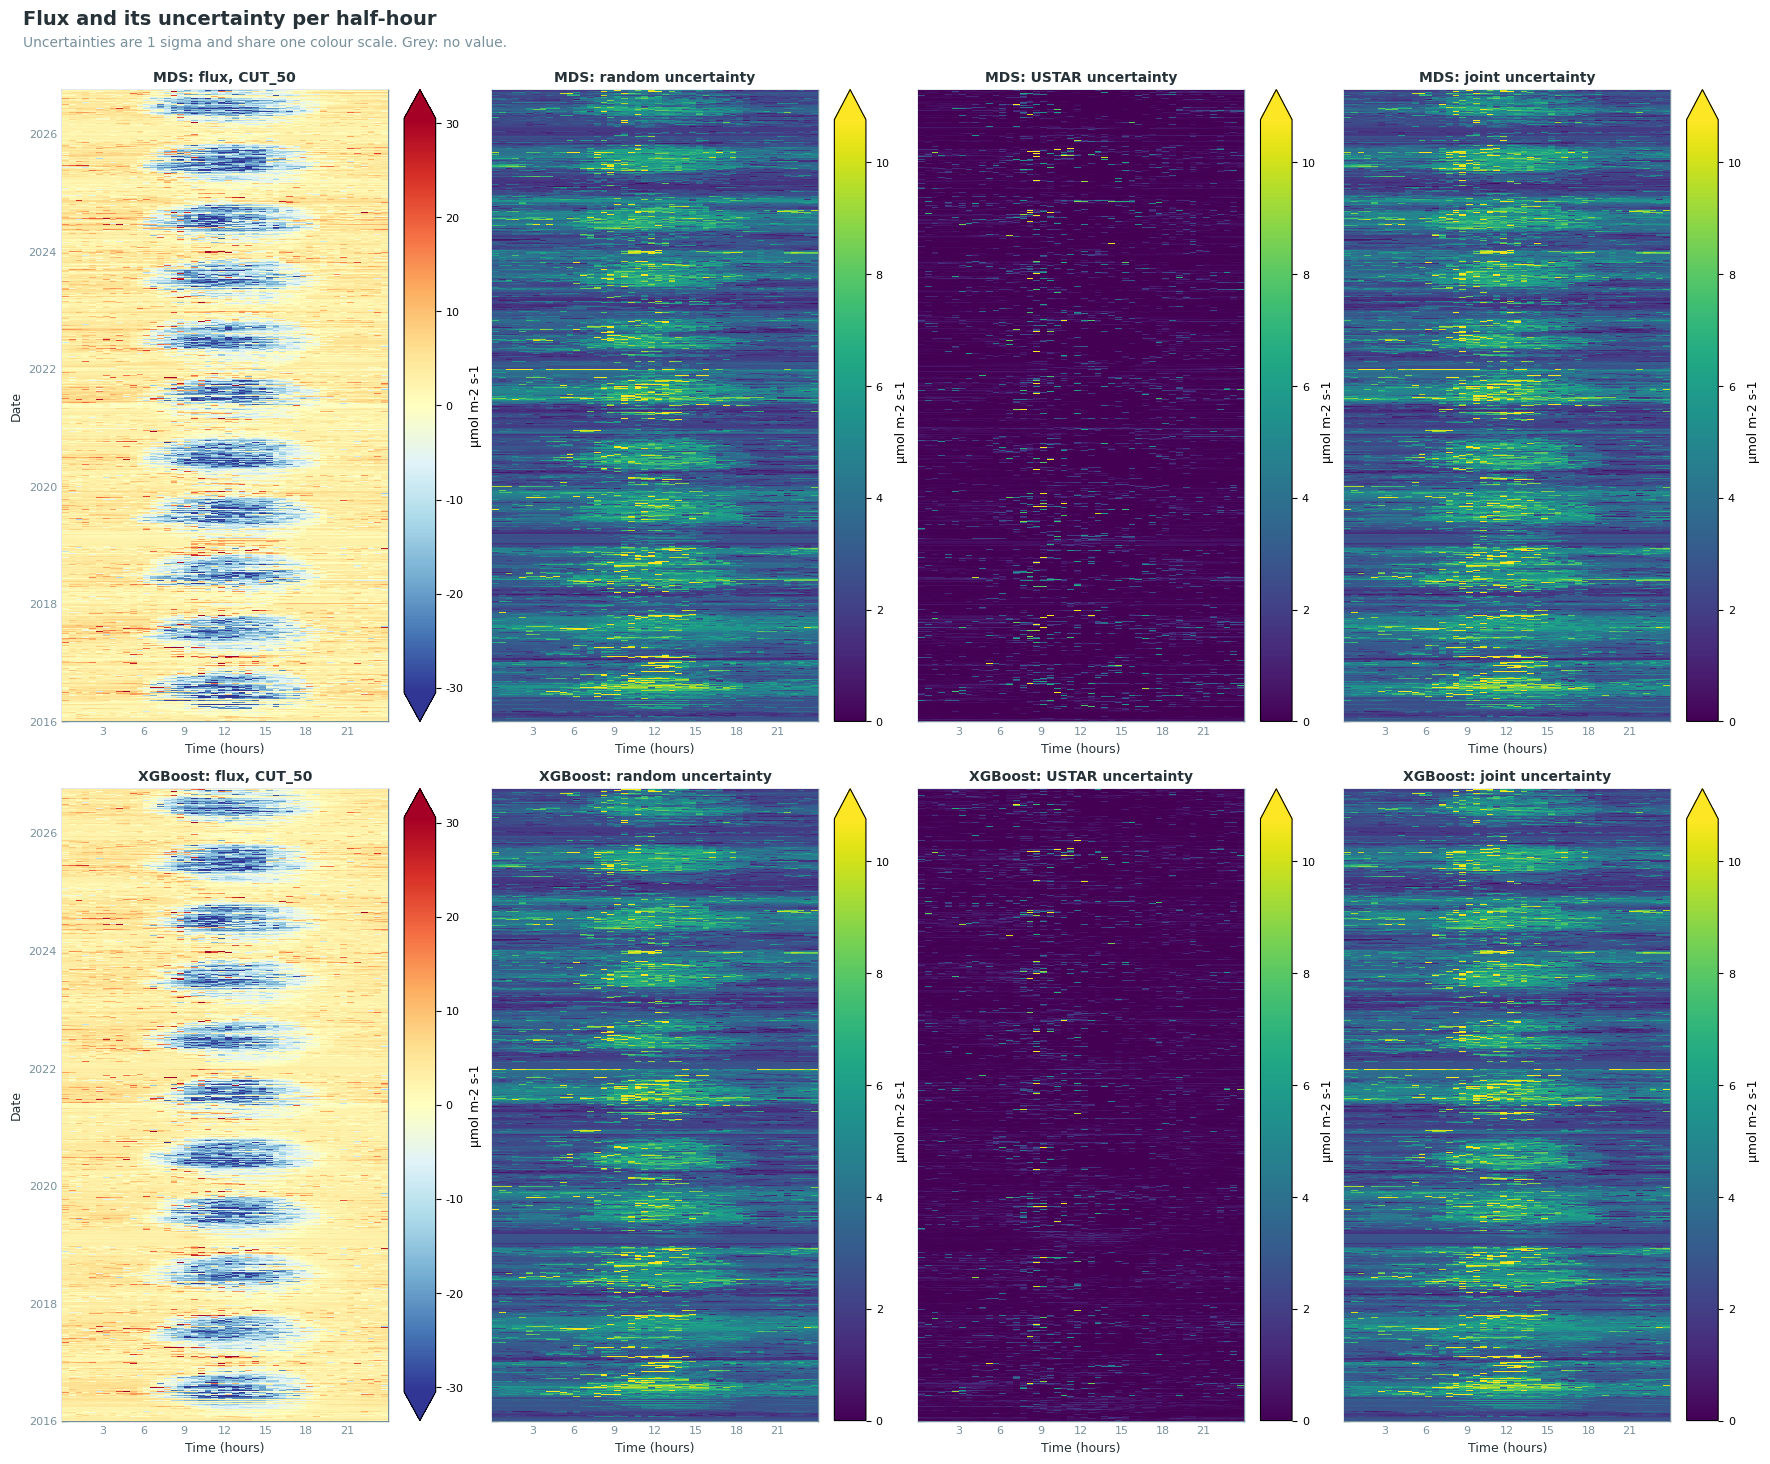

In [62]:
# The flux and its three uncertainties per half-hour. All fluxes share one colour scale, all
# uncertainties another.
_methods = list(UNC_FRAMES)
_flim = max(float(_m[GF_COLS[_k][UNC_REF]].abs().quantile(0.99)) for _k in _methods)
_ulim = max(float(UNC[_k][f'{GF_COLS[_k][UNC_REF]}_JOINTUNC'].quantile(0.99)) for _k in _methods)
fig, axs = plt.subplots(len(_methods), 4, figsize=(17.6, 7 * len(_methods) + 0.6), sharey=True,
                        layout='constrained', squeeze=False)
for _row, _method in zip(axs, _methods):
    _gf = GF_COLS[_method][UNC_REF]
    _name = METHOD_NAMES.get(_method, _method)
    _panels = [
        (f'{_name}: flux, {UNC_REF}', _m[_gf], cp.HEATMAP_CMAP, -_flim, _flim, 'both'),
        (f'{_name}: random uncertainty', UNC[_method][f'{_gf}_RANDUNC'], 'viridis', 0, _ulim, 'max'),
        (f'{_name}: USTAR uncertainty', UNC[_method][f'{_gf}_USTARUNC'], 'viridis', 0, _ulim, 'max'),
        (f'{_name}: joint uncertainty', UNC[_method][f'{_gf}_JOINTUNC'], 'viridis', 0, _ulim, 'max'),
    ]
    for _j, (_ax, (_title, _series, _cmap, _vmin, _vmax, _extend)) in enumerate(zip(_row, _panels)):
        dv.plotting.HeatmapDateTime(series=_series, verbose=False).plot(
            ax=_ax, fig=fig, vmin=_vmin, vmax=_vmax, cmap=_cmap, cb_extend=_extend,
            cb_digits_after_comma='auto', cb_labelsize=8, zlabel=FLUX_UNITS,
            color_bad=cp.NAN_COLOR, as_image=True, format_style=cp.heatmap_style(_title))
        # The unit label next to its colour bar, not halfway to the next panel.
        _cb = _ax.images[-1].colorbar if _ax.images else None
        if _cb is not None:
            _cb.set_label(FLUX_UNITS, size=9, labelpad=4)
        if _j:
            plt.setp(_ax.get_yticklabels(), visible=False)
            _ax.yaxis.get_label().set_visible(False)
cp.figure_title(fig, 'Flux and its uncertainty per half-hour',
                'Uncertainties are 1 sigma and share one colour scale. Grey: no value.')
plt.show()

## 💾 Step 13: export

The output file holds only what this notebook adds: every column the chain created and the three
uncertainty columns of Step 12 for each gap-filling method. The input columns stay unchanged in the
input file; the merge into the fullset joins the outputs of the flux notebooks with it on the
timestamp.

In [63]:
# Only the new columns: the input columns are in the input file and are added back in the merge.
_all = data.merged_df().join(UNC_EXPORT)
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
assert set(UNC_EXPORT.columns) <= set(out_df.columns), "uncertainty columns missing from the output"
print(f"Uncertainty columns in the output: {list(UNC_EXPORT.columns)}")
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns (input columns left out: "
      f"{_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 65 (L2: 12, L3.1: 9, L3.2: 11, L3.3: 21, 
L4.1: 12)

> No variables in the input data were overwritten, only new variables added.

Uncertainty columns in the output: ['NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_JOINTUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_JOINTUNC']
188,448 records x 76 columns (input columns left out: 347)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\01_FPPC_IRGA72_NEE_2016-2026.09.parquet (0.598 seconds).

***

# End of notebook.

In [64]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-27 01:39:09
Finished: 2026-10-27 01:57:10
Runtime:  00:18:00 (hh:mm:ss)
